# LaLiga con ojos de casa de apuestas: EDA para modelar

En fútbol el trabajo de un trader es distinto al de la NFL. Hay tres resultados posibles (local, empate, visitante), se anotan pocos goles y por eso la varianza es enorme: un equipo puede dominar y perder 0-1. Las preguntas son las mismas, pero las respuestas cambian:

1. **¿Qué tan bueno es el mercado?** ¿Cuánto cobra la casa, cómo se le quita el margen a una cuota y dónde se equivoca (sesgo favorito-longshot)?
2. **¿Qué forma tienen los resultados?** ¿Los goles siguen una Poisson? ¿Hay más empates de lo que predice el modelo simple? ¿Cuándo se anotan los goles?
3. **¿Qué señales son reales?** ¿Qué estadísticas de un equipo predicen sus puntos futuros y cuáles son suerte?

Al final hay un predictor de partidos que combina todo y se compara contra el mercado.

**Para correrlo:** `pip install pandas numpy matplotlib scipy statsmodels`. Todo se descarga solo la primera vez y queda guardado en una carpeta local.

**Datos**
* **Club Football Match Data (football-data.co.uk):** todos los partidos de Primera y Segunda desde 2000/01 con goles, medio tiempo, tiros, tiros al arco, corners, tarjetas, cuotas de Bet365, la mejor cuota de ~17 casas, over/under 2.5 y hándicap asiático. Las cuotas se toman antes del partido (normalmente el viernes), no son las de cierre.
* **openfootball:** resultados de la temporada en curso y, para 2025/26, el minuto de cada gol.
* **StatMuse (snapshot del 17 de octubre de 2026):** xG, xGA y posesión de la temporada 2026/27, cargados a mano en la sección del predictor.

In [1]:
import re
import warnings
from pathlib import Path
import urllib.request

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy import stats
from scipy.spatial import cKDTree
from scipy.optimize import minimize_scalar
import statsmodels.api as sm

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

DATA = Path("data_laliga")
DATA.mkdir(exist_ok=True)
MATCHES_URL = "https://raw.githubusercontent.com/xgabora/Club-Football-Match-Data-2000-2025/main/data/Matches.csv"
OPENFOOTBALL = "https://raw.githubusercontent.com/openfootball/espana/master/{}/1-liga.txt"

C = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "yellow": "#eda100",
     "violet": "#6250d6", "red": "#e34948", "ink": "#0b0b0b", "ink2": "#52514e",
     "muted": "#898781", "grid": "#e1e0d9", "base": "#c3c2b7", "surface": "#fcfcfb", "mid": "#f0efec"}
mpl.rcParams.update({
    "figure.facecolor": C["surface"], "axes.facecolor": C["surface"], "savefig.facecolor": C["surface"],
    "axes.edgecolor": C["base"], "axes.labelcolor": C["ink2"], "axes.titlecolor": C["ink"],
    "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.labelsize": 9.5,
    "xtick.color": C["muted"], "ytick.color": C["muted"], "xtick.labelsize": 8.5, "ytick.labelsize": 8.5,
    "axes.grid": True, "grid.color": C["grid"], "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False, "legend.fontsize": 8.5,
    "lines.linewidth": 2, "figure.dpi": 110, "font.size": 9.5,
})
DIVERGING = mpl.colors.LinearSegmentedColormap.from_list("div", [C["red"], C["mid"], C["blue"]])


def fetch(url, path):
    path = Path(path)
    if not path.exists():
        urllib.request.urlretrieve(url, path)
    return path


def wilson(k, n, z=1.96):
    k, n = np.asarray(k, float), np.asarray(n, float)
    p = k / n
    den = 1 + z**2 / n
    mid = (p + z**2 / (2 * n)) / den
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / den
    return mid - half, mid + half


def season_of(d):
    """La temporada empieza en agosto: 2025 = 2025/26."""
    return d.year if d.month >= 8 else d.year - 1


def label(s):
    return f"{s}/{str(s + 1)[-2:]}"


# Métodos para quitar el margen de la casa (filas = partidos, columnas = resultados)
def devig_mult(inv):
    return inv / inv.sum(1, keepdims=True)


def devig_power(inv, iters=60):
    lo, hi = np.ones(len(inv)), np.full(len(inv), 5.0)
    for _ in range(iters):
        k = (lo + hi) / 2
        s = (inv ** k[:, None]).sum(1)
        lo, hi = np.where(s > 1, k, lo), np.where(s > 1, hi, k)
    return inv ** ((lo + hi) / 2)[:, None]


def devig_shin(inv, iters=60):
    B = inv.sum(1, keepdims=True)
    lo, hi = np.zeros((len(inv), 1)), np.full((len(inv), 1), 0.5)
    for _ in range(iters):
        z = (lo + hi) / 2
        p = (np.sqrt(z**2 + 4 * (1 - z) * inv**2 / B) - z) / (2 * (1 - z))
        s = p.sum(1, keepdims=True)
        lo, hi = np.where(s > 1, z, lo), np.where(s > 1, hi, z)
    z = (lo + hi) / 2
    p = (np.sqrt(z**2 + 4 * (1 - z) * inv**2 / B) - z) / (2 * (1 - z))
    return p / p.sum(1, keepdims=True)

## 1. Datos y control de calidad

Cargo Primera División (SP1) y reviso por temporada qué variables existen: no todas las temporadas tienen tiros o cuotas de over/under. Esto define qué periodo usar en cada análisis.

In [2]:
raw = pd.read_csv(fetch(MATCHES_URL, DATA / "Matches.csv"), low_memory=False, parse_dates=["MatchDate"])
cols = {"MatchDate": "date", "HomeTeam": "home", "AwayTeam": "away", "FTHome": "hg", "FTAway": "ag",
        "FTResult": "res", "HTHome": "hthg", "HTAway": "htag", "HomeShots": "hs", "AwayShots": "as_",
        "HomeTarget": "hst", "AwayTarget": "ast", "HomeCorners": "hc", "AwayCorners": "ac",
        "HomeYellow": "hy", "AwayYellow": "ay", "HomeRed": "hr", "AwayRed": "ar",
        "OddHome": "oH", "OddDraw": "oD", "OddAway": "oA", "MaxHome": "xH", "MaxDraw": "xD", "MaxAway": "xA",
        "Over25": "o25", "Under25": "u25", "HandiSize": "ah", "HomeElo": "elo_h", "AwayElo": "elo_a",
        "Division": "division"}
spain = raw[raw["Division"].isin(["SP1", "SP2"])].rename(columns=cols)[list(cols.values())].copy()
spain = spain[spain["hg"].notna()]
spain["season"] = spain["date"].map(season_of)
m = spain[spain["division"] == "SP1"].sort_values("date").reset_index(drop=True)
m["res"] = np.select([m["hg"] > m["ag"], m["hg"] == m["ag"]], ["H", "D"], "A")

quality = m.groupby("season").agg(
    partidos=("hg", "size"), cuotas_1X2=("oH", lambda s: s.notna().mean()),
    mejor_cuota=("xH", lambda s: s.notna().mean()), over_under=("o25", lambda s: s.notna().mean()),
    tiros=("hs", lambda s: s.notna().mean()), corners=("hc", lambda s: s.notna().mean()),
    goles_partido=("hg", lambda s: (s + m.loc[s.index, "ag"]).mean()))
quality.index = quality.index.map(label)
print(f"{len(m):,} partidos de Primera, {m['season'].min()}/{m['season'].min() + 1} a hoy (último: {m['date'].max():%d %b %Y})")
quality

9,419 partidos de Primera, 2000/2001 a hoy (último: 03 Sep 2026)


,partidos,cuotas_1X2,mejor_cuota,over_under,tiros,corners,goles_partido
season,,,,,,,
2000/01,380,0.989,0.000,0.000,0.000,0.000,2.882
2001/02,380,0.789,0.000,0.000,0.000,0.000,2.529
2002/03,380,0.997,0.000,0.000,0.000,0.000,2.674
2003/04,380,0.987,0.000,0.000,0.000,0.000,2.671
2004/05,268,1.000,0.000,0.000,0.000,0.000,2.586
2005/06,380,1.000,1.000,1.000,1.000,1.000,2.463
2007/08,380,1.000,1.000,1.000,1.000,1.000,2.687
2008/09,380,1.000,1.000,1.000,1.000,1.000,2.897
2009/10,380,1.000,1.000,0.997,1.000,1.000,2.713


> **Calidad de la data**
> * 9,419 partidos de Primera desde 2000/01. Falta la temporada 2006/07 completa y 2004/05 está incompleta (268 de 380 partidos).
> * Tiros, corners, mejor cuota y over/under existen desde 2005/06, así que los análisis de estadísticas y de goles esperados usan ese periodo.
> * Los goles por partido se mueven entre 2.5 y 2.9; las últimas tres temporadas rondan 2.6 a 2.7.

## 2. El mercado como benchmark

### 2.1 Cuánto cobra la casa

El **overround** es la suma de las probabilidades implícitas (1 / cuota) menos 1. En 1X2 de fútbol es más alto que en la NFL porque hay tres resultados. La "mejor cuota" toma el máximo entre ~17 casas para cada resultado: es lo que obtiene un apostador que compara precios (line shopping).

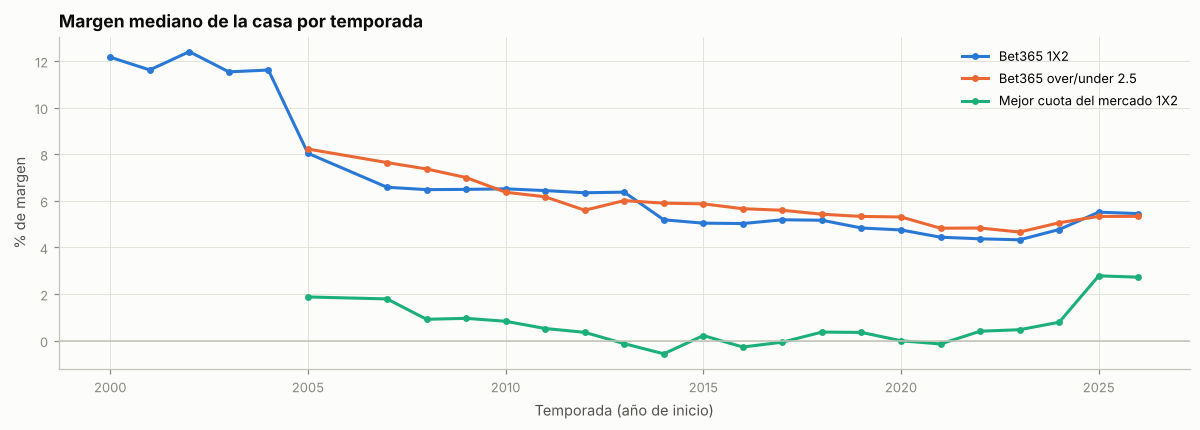

,1X2 Bet365,1X2 mejor cuota,O/U 2.5 Bet365
season,,,
2021,4.440,-0.140,4.830
2022,4.370,0.410,4.840
2023,4.330,0.470,4.660
2024,4.770,0.790,5.060
2025,5.520,2.780,5.330
2026,5.450,2.730,5.330


In [3]:
mk = m.dropna(subset=["oH", "oD", "oA"]).copy()
inv = 1 / mk[["oH", "oD", "oA"]].values
mk["margen_1x2"] = inv.sum(1) - 1
mk["margen_mejor"] = (1 / mk[["xH", "xD", "xA"]]).sum(1, min_count=3) - 1
mk["margen_ou"] = (1 / mk["o25"] + 1 / mk["u25"]) - 1   # NaN si falta alguna cuota
over = mk.groupby("season")[["margen_1x2", "margen_mejor", "margen_ou"]].median() * 100

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(over.index, over["margen_1x2"], color=C["blue"], marker="o", ms=3.5, label="Bet365 1X2")
ax.plot(over.index, over["margen_ou"], color=C["orange"], marker="o", ms=3.5, label="Bet365 over/under 2.5")
ax.plot(over.index, over["margen_mejor"], color=C["aqua"], marker="o", ms=3.5, label="Mejor cuota del mercado 1X2")
ax.axhline(0, color=C["base"], lw=1)
ax.set(title="Margen mediano de la casa por temporada", xlabel="Temporada (año de inicio)", ylabel="% de margen")
ax.legend()
plt.tight_layout()
plt.show()
over.round(2).tail(6).set_axis(["1X2 Bet365", "1X2 mejor cuota", "O/U 2.5 Bet365"], axis=1)

### 2.2 Cómo quitar el margen: tres métodos

Para convertir cuotas en probabilidades hay que repartir el margen entre los tres resultados. Hay varias teorías:

* **Multiplicativo:** reparte el margen en proporción a cada probabilidad. Es el más usado y el más ingenuo.
* **Power:** eleva cada probabilidad a un exponente k para que sumen 1. Le quita más margen a los resultados improbables.
* **Shin:** modela que una parte de los apostadores tiene información privilegiada y la casa se protege cargando más margen en los longshots. Štrumbelj (2014) mostró que suele dar las probabilidades más precisas.

Comparo los tres con log loss y Brier score (más bajo es mejor) desde 2005/06, y con dos referencias: probabilidades iguales (1/3) y las frecuencias históricas de local, empate y visitante.

Partidos evaluados: 7,631


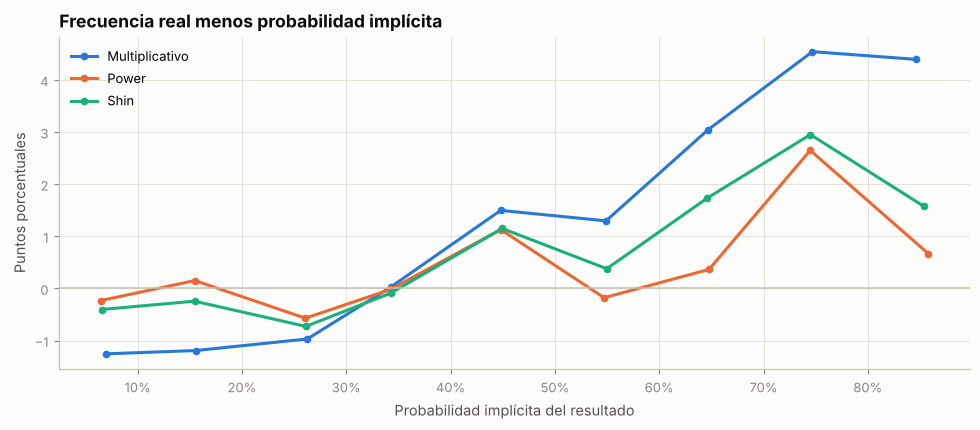

,log_loss,brier
Power,0.959,0.569
Shin,0.960,0.569
Multiplicativo,0.960,0.570
Frecuencia histórica,1.059,0.639
Uniforme (1/3),1.099,0.667


In [4]:
ev = mk[mk["season"] >= 2005].copy()
inv = 1 / ev[["oH", "oD", "oA"]].values
y = ev["res"].map({"H": 0, "D": 1, "A": 2}).values
Y = np.eye(3)[y]
methods = {"Multiplicativo": devig_mult(inv), "Power": devig_power(inv), "Shin": devig_shin(inv)}
base = np.tile(Y.mean(0), (len(Y), 1))
methods_eval = {**methods, "Frecuencia histórica": base, "Uniforme (1/3)": np.full_like(Y, 1 / 3)}
scores = pd.DataFrame({name: {"log_loss": -np.mean(np.log(P[np.arange(len(P)), y])),
                              "brier": np.mean(((P - Y) ** 2).sum(1))}
                       for name, P in methods_eval.items()}).T.sort_values("log_loss")
print(f"Partidos evaluados: {len(ev):,}")

# Calibración por tramo de probabilidad, juntando los tres resultados
bins = np.array([0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 1.0])
fig, ax = plt.subplots(figsize=(9, 4))
for (name, P), col in zip(methods.items(), [C["blue"], C["orange"], C["aqua"]]):
    p, o = P.ravel(), Y.ravel()
    b = pd.cut(p, bins)
    t = pd.DataFrame({"p": p, "o": o, "b": b}).groupby("b", observed=True).agg(p=("p", "mean"), o=("o", "mean"), n=("o", "size"))
    ax.plot(t["p"], (t["o"] - t["p"]) * 100, marker="o", ms=4, color=col, label=name)
ax.axhline(0, color=C["base"], lw=1)
ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1))
ax.set(title="Frecuencia real menos probabilidad implícita", xlabel="Probabilidad implícita del resultado",
       ylabel="Puntos porcentuales")
ax.legend()
plt.tight_layout()
plt.show()
scores

> **Lo que dice la data**
> * El margen de Bet365 en 1X2 bajó de 12% en 2000 a 4.4% en 2021 a 2023, y volvió a subir a 5.5% en 2025 y 2026. La mejor cuota del mercado tuvo margen cercano a 0% (a veces negativo, o sea arbitraje) hasta 2023 y ahora ronda 2.8%; parte de ese salto puede ser un cambio en las casas que usa la fuente.
> * Los tres métodos para quitar el margen dan casi la misma precisión total (log loss de 0.959 a 0.960) y todos le ganan por mucho a las frecuencias históricas (1.059).
> * La diferencia está en los extremos. El multiplicativo sobrestima a los longshots (1.2 puntos de más en los de menos de 10%) y subestima a los favoritos (4.5 puntos de menos alrededor de 75%). Power y Shin corrigen buena parte, pero los favoritos siguen ganando unos 3 puntos más de lo implícito.
>
> **Para el modelo:** usa Shin o power para convertir cuotas en probabilidades. El multiplicativo deja un sesgo justo donde más se apuesta.

## 3. Sesgo favorito-longshot: ¿dónde pierde más el apostador?

Apuesto 1 unidad a cada resultado de cada partido, al precio de Bet365 y a la mejor cuota del mercado, y mido el retorno según la probabilidad implícita. Si el sesgo existe, los resultados improbables (longshots) devuelven mucho menos que los favoritos.

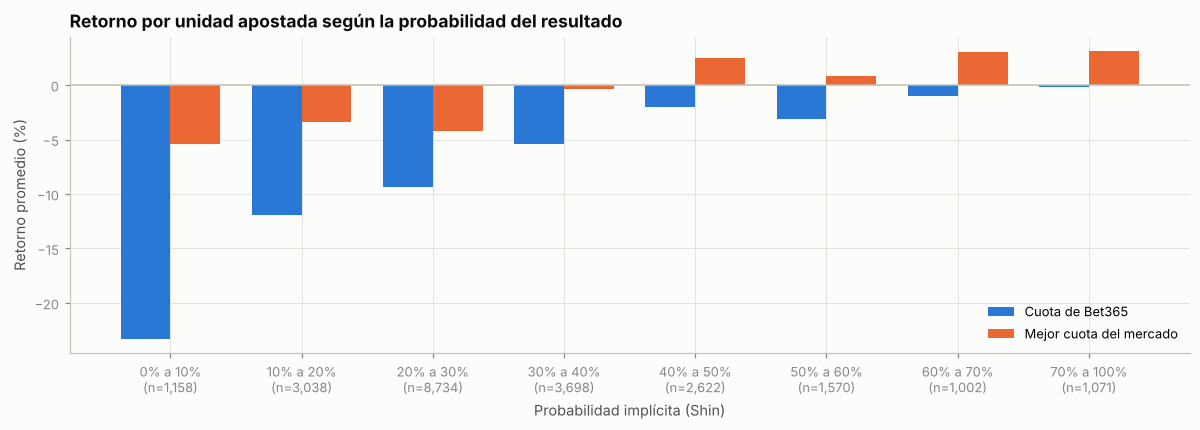

,apuestas,prob_media,acierto,roi_bet365,roi_mejor_cuota
tramo,,,,,
"(0.0, 0.1]",1158,0.065,0.061,-0.233,-0.054
"(0.1, 0.2]",3038,0.155,0.152,-0.119,-0.034
"(0.2, 0.3]",8734,0.261,0.254,-0.093,-0.042
"(0.3, 0.4]",3698,0.343,0.342,-0.054,-0.004
"(0.4, 0.5]",2622,0.450,0.461,-0.020,0.024
"(0.5, 0.6]",1570,0.550,0.554,-0.031,0.009
"(0.6, 0.7]",1002,0.646,0.664,-0.010,0.030
"(0.7, 1.0]",1071,0.791,0.815,-0.002,0.031


,apuestas,acierto,prob_media,roi_bet365,roi_mejor_cuota
resultado,,,,,
Empate,7631,0.249,0.252,-0.093,-0.040
Local,7631,0.468,0.459,-0.031,0.022
Visitante,7631,0.283,0.289,-0.107,-0.035


In [5]:
rows = []
for k, (oc, xc) in enumerate([("oH", "xH"), ("oD", "xD"), ("oA", "xA")]):
    d = ev[[oc, xc]].copy()
    d.columns = ["odds", "best"]
    d["won"] = (y == k).astype(int)
    d["prob"] = methods["Shin"][:, k]
    d["resultado"] = ["Local", "Empate", "Visitante"][k]
    rows.append(d)
bets = pd.concat(rows, ignore_index=True)
bets["roi_bet365"] = bets["won"] * bets["odds"] - 1
bets["roi_mejor"] = bets["won"] * bets["best"] - 1
bets["tramo"] = pd.cut(bets["prob"], [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 1.0])
roi = bets.groupby("tramo", observed=True).agg(apuestas=("won", "size"), prob_media=("prob", "mean"),
                                               acierto=("won", "mean"), roi_bet365=("roi_bet365", "mean"),
                                               roi_mejor_cuota=("roi_mejor", "mean"))

fig, ax = plt.subplots(figsize=(11, 4))
x = np.arange(len(roi))
w = 0.38
ax.bar(x - w / 2, roi["roi_bet365"] * 100, w, color=C["blue"], label="Cuota de Bet365")
ax.bar(x + w / 2, roi["roi_mejor_cuota"] * 100, w, color=C["orange"], label="Mejor cuota del mercado")
ax.axhline(0, color=C["base"], lw=1)
ax.set_xticks(x, [f"{i.left:.0%} a {i.right:.0%}\n(n={n:,})" for i, n in zip(roi.index, roi["apuestas"])])
ax.set(title="Retorno por unidad apostada según la probabilidad del resultado", xlabel="Probabilidad implícita (Shin)",
       ylabel="Retorno promedio (%)")
ax.legend()
plt.tight_layout()
plt.show()

by_outcome = bets.groupby("resultado").agg(apuestas=("won", "size"), acierto=("won", "mean"), prob_media=("prob", "mean"),
                                           roi_bet365=("roi_bet365", "mean"), roi_mejor_cuota=("roi_mejor", "mean"))
display(roi)
by_outcome

> **Lo que dice la data**
> * El sesgo favorito-longshot es fuerte en LaLiga: apostar a resultados con menos de 10% de probabilidad devuelve -23% por unidad en Bet365; a los de 70% o más, -0.2%.
> * Por tipo de resultado, el visitante (-10.7%) y el empate (-9.3%) son las peores apuestas; el local pierde solo -3.1%.
> * Con la mejor cuota del mercado, apostar a favoritos de 40% o más dio entre +1% y +3%, y al local +2.2%. **Cuidado:** la mejor cuota es el máximo entre ~17 casas antes del partido. Esos precios duran poco, tienen límites bajos y las casas limitan a quien los toma de forma sistemática.
>
> **Para el modelo:** el margen de la casa no se reparte parejo. Si tu modelo encuentra "valor" en un longshot, lo más probable es que sea el margen escondido y no un error del mercado.

## 4. Ventaja de local

La ventaja de local en el fútbol europeo viene cayendo hace décadas, y la pandemia fue un experimento natural: entre junio de 2020 y mayo de 2021 se jugó sin público. Mido la ventaja de local por temporada y comparo tres periodos.

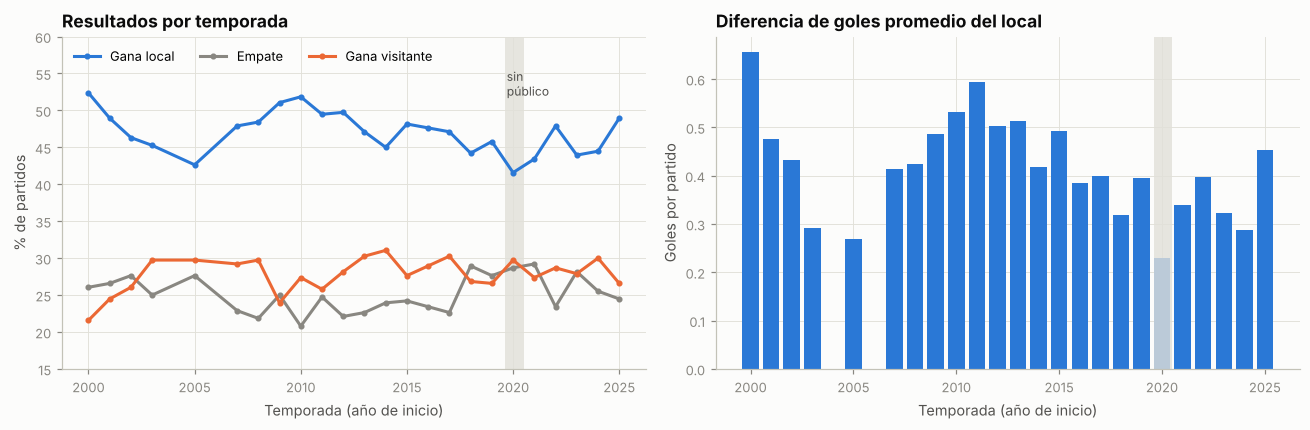

,partidos,local,empate,visita,dif_goles,pts_local,pts_visita
periodo,,,,,,,
Antes (2000 a mar 2020),6998,0.480,0.247,0.274,0.450,1.686,1.067
Después (2021/22 en adelante),1931,0.458,0.262,0.280,0.364,1.636,1.102
Sin público (jun 2020 a may 2021),490,0.414,0.284,0.302,0.220,1.527,1.190


In [6]:
m["gd"] = m["hg"] - m["ag"]
m["pts_h"] = np.select([m["res"] == "H", m["res"] == "D"], [3, 1], 0)
m["pts_a"] = np.select([m["res"] == "A", m["res"] == "D"], [3, 1], 0)
ghost = (m["date"] >= "2020-06-11") & (m["date"] <= "2021-05-31")
m["periodo"] = np.select([ghost, m["date"] < "2020-06-11"], ["Sin público (jun 2020 a may 2021)", "Antes (2000 a mar 2020)"],
                         "Después (2021/22 en adelante)")

hs = m.groupby("season").filter(lambda d: len(d) >= 300).groupby("season").agg(local=("res", lambda s: (s == "H").mean()), empate=("res", lambda s: (s == "D").mean()),
                             visita=("res", lambda s: (s == "A").mean()), dif_goles=("gd", "mean"))
per = m.groupby("periodo").agg(partidos=("gd", "size"), local=("res", lambda s: (s == "H").mean()),
                               empate=("res", lambda s: (s == "D").mean()), visita=("res", lambda s: (s == "A").mean()),
                               dif_goles=("gd", "mean"), pts_local=("pts_h", "mean"), pts_visita=("pts_a", "mean"))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ax = axes[0]
for col, c, name in [("local", C["blue"], "Gana local"), ("empate", C["muted"], "Empate"), ("visita", C["orange"], "Gana visitante")]:
    ax.plot(hs.index, hs[col] * 100, color=c, marker="o", ms=3, label=name)
ax.axvspan(2019.6, 2020.5, color=C["grid"], alpha=0.8, lw=0)
ax.text(2019.7, 52, "sin\npúblico", fontsize=8, color=C["ink2"])
ax.set(title="Resultados por temporada", xlabel="Temporada (año de inicio)", ylabel="% de partidos")
ax.legend(ncol=3, loc="upper left")
ax.set_ylim(15, 60)
ax = axes[1]
ax.bar(hs.index, hs["dif_goles"], color=C["blue"])
ax.axvspan(2019.6, 2020.5, color=C["grid"], alpha=0.8, lw=0)
ax.set(title="Diferencia de goles promedio del local", xlabel="Temporada (año de inicio)", ylabel="Goles por partido")
plt.tight_layout()
plt.show()
per

### 4.1 Lo que el mercado espera: de cuotas a goles esperados

Un trader de fútbol piensa en goles esperados, no en cuotas. Con el 1X2 (sin margen, Shin) y el over/under 2.5 se pueden recuperar los goles esperados de cada equipo según el mercado (λ local y λ visitante), buscando el par de Poisson que reproduce esas tres probabilidades.

Con esos λ obtengo la **ventaja de local que el mercado espera** cada temporada, en goles, y la comparo con la real.

Partidos con 1X2 y over/under: 7,630 | error mediano del ajuste: 0.0127


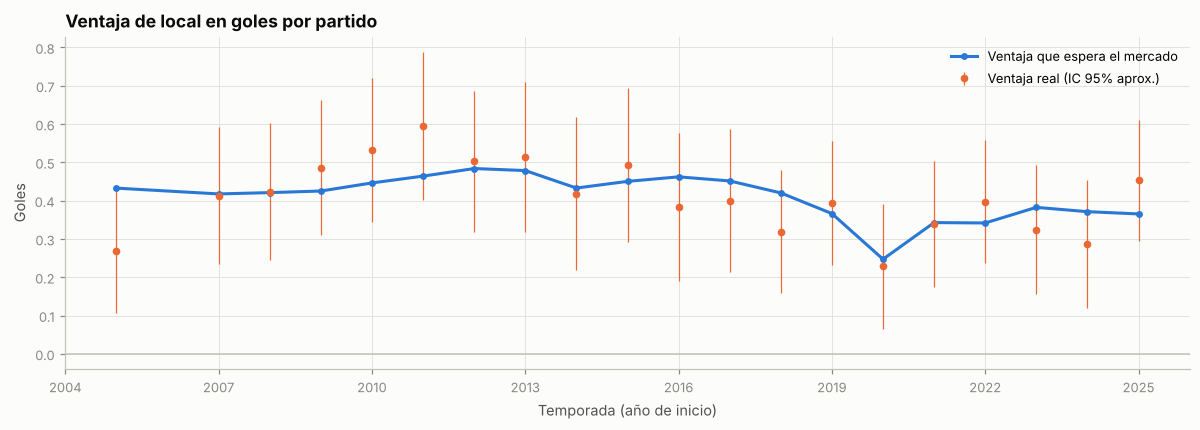

,mercado,real,se
temporada,,,
2018,0.420,0.318,0.082
2019,0.366,0.395,0.083
2020,0.247,0.229,0.083
2021,0.343,0.339,0.084
2022,0.342,0.397,0.082
2023,0.382,0.324,0.086
2024,0.371,0.287,0.085
2025,0.365,0.453,0.081


In [7]:
# Tabla de Poisson: para cada par (λ local, λ visita) calcula P(local), P(visita) y P(over 2.5)
lam = np.arange(0.05, 4.01, 0.025)
G = np.arange(0, 11)
pmf = stats.poisson.pmf(G[None, :], lam[:, None])
LH, LA = np.meshgrid(np.arange(len(lam)), np.arange(len(lam)), indexing="ij")
joint = pmf[LH.ravel()][:, :, None] * pmf[LA.ravel()][:, None, :]
gi, gj = np.meshgrid(G, G, indexing="ij")
grid_h = (joint * (gi > gj)).sum((1, 2))
grid_a = (joint * (gi < gj)).sum((1, 2))
grid_o = (joint * ((gi + gj) > 2.5)).sum((1, 2))
tree = cKDTree(np.c_[grid_h, grid_a, grid_o])

ou = m.dropna(subset=["oH", "oD", "oA", "o25", "u25"]).copy()
p3 = devig_shin(1 / ou[["oH", "oD", "oA"]].values)
p_over = (1 / ou["o25"]) / (1 / ou["o25"] + 1 / ou["u25"])
dist, idx = tree.query(np.c_[p3[:, 0], p3[:, 2], p_over])
ou["lam_h"], ou["lam_a"] = lam[LH.ravel()[idx]], lam[LA.ravel()[idx]]
ou["p_h"], ou["p_d"], ou["p_a"], ou["p_over"] = p3[:, 0], p3[:, 1], p3[:, 2], p_over.values
ou["ajuste"] = dist
print(f"Partidos con 1X2 y over/under: {len(ou):,} | error mediano del ajuste: {np.median(dist):.4f}")


def ratings_ls(d, target, hfa_col=True):
    """target = ventaja_local + r_local - r_visita (ratings suman cero)."""
    teams = sorted(set(d["home"]) | set(d["away"]))
    ix = {t: i for i, t in enumerate(teams)}
    X = np.zeros((len(d) + 1, len(teams) + 1))
    for r, (h, a) in enumerate(zip(d["home"], d["away"])):
        X[r, ix[h]], X[r, ix[a]], X[r, -1] = 1, -1, 1
    X[-1, :len(teams)] = 1
    beta, *_ = np.linalg.lstsq(X, np.r_[d[target].values, 0], rcond=None)
    return pd.Series(beta[:-1], index=teams), beta[-1]


ou["sup"] = ou["lam_h"] - ou["lam_a"]
hfa = []
for s, d in ou.groupby("season"):
    if len(d) < 300:
        continue
    _, h_mkt = ratings_ls(d, "sup")
    _, h_real = ratings_ls(d, "gd")
    se = d["gd"].std() / np.sqrt(len(d))
    hfa.append({"temporada": s, "mercado": h_mkt, "real": h_real, "se": se})
hfa = pd.DataFrame(hfa).set_index("temporada")

fig, ax = plt.subplots(figsize=(11, 4))
ax.errorbar(hfa.index, hfa["real"], yerr=1.96 * hfa["se"], fmt="o", color=C["orange"], ms=4, lw=0.8,
            label="Ventaja real (IC 95% aprox.)")
ax.plot(hfa.index, hfa["mercado"], color=C["blue"], marker="o", ms=3.5, label="Ventaja que espera el mercado")
ax.axhline(0, color=C["base"], lw=1)
ax.set(title="Ventaja de local en goles por partido", xlabel="Temporada (año de inicio)", ylabel="Goles")
ax.xaxis.set_major_locator(mpl.ticker.MaxNLocator(integer=True))
ax.legend()
plt.tight_layout()
plt.show()
hfa.round(3).tail(8)

> **Lo que dice la data**
> * Antes de la pandemia el local ganaba 48.0% de los partidos con 0.45 goles de diferencia promedio. Sin público bajó a 41.4% y 0.22 goles. Después se recuperó a 45.8% y 0.36 goles, todavía por debajo del nivel previo.
> * El mercado anticipó bien la caída: esperaba 0.25 goles de ventaja en 2020/21 y la real fue 0.23. Hoy espera unos 0.37 goles.
> * En 2025/26 la ventaja real fue 0.45 goles contra 0.37 esperados, dentro del ruido normal de una temporada.
>
> **Para el modelo:** la ventaja de local hoy vale entre 0.35 y 0.4 goles, un factor de ~1.3 sobre los goles del local. Hay que reestimarla cada temporada.

## 5. La forma de los resultados: goles y Poisson

El modelo base del fútbol supone que los goles de cada equipo siguen una Poisson independiente. Si eso fuera cierto, con los λ del mercado podría predecir la frecuencia de cada marcador. Comparo marcadores reales contra esperados: un valor mayor que 1 significa que ese marcador pasa más de lo que dice la Poisson independiente.

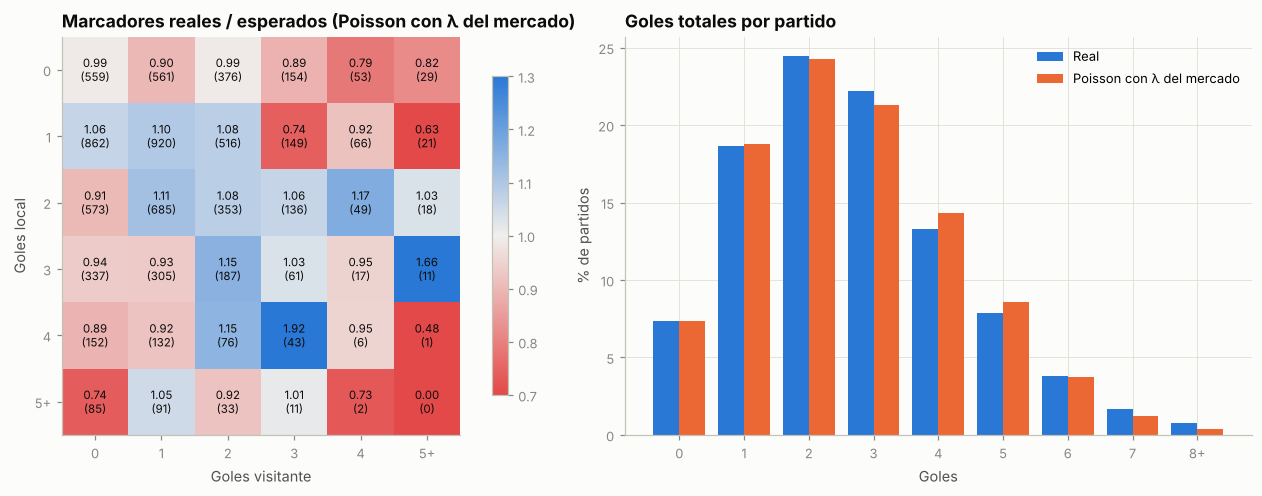

Empates reales: 24.9% | Poisson independiente con λ del mercado: 23.5% | precio de empate del mercado (Shin): 25.2%
0-0 real 7.3% vs esperado 7.4% | 1-1 real 12.1% vs esperado 11.0%


In [8]:
lam_h, lam_a = ou["lam_h"].values, ou["lam_a"].values
K = 6  # 0 a 5+
ph = stats.poisson.pmf(np.arange(K)[None, :], lam_h[:, None]); ph[:, -1] = 1 - ph[:, :-1].sum(1)
pa = stats.poisson.pmf(np.arange(K)[None, :], lam_a[:, None]); pa[:, -1] = 1 - pa[:, :-1].sum(1)
expected = np.einsum("ni,nj->ij", ph, pa)
actual = pd.crosstab(ou["hg"].astype(int).clip(upper=K - 1), ou["ag"].astype(int).clip(upper=K - 1)).reindex(index=range(K), columns=range(K), fill_value=0).values
ratio = actual / expected

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
ax = axes[0]
im = ax.imshow(ratio, cmap=DIVERGING, vmin=0.7, vmax=1.3)
for i in range(K):
    for j in range(K):
        ax.text(j, i, f"{ratio[i, j]:.2f}\n({actual[i, j]:,})", ha="center", va="center", fontsize=7.5, color=C["ink"])
ticks = [str(t) for t in range(K - 1)] + [f"{K - 1}+"]
ax.set_xticks(range(K), ticks); ax.set_yticks(range(K), ticks)
ax.set(title="Marcadores reales / esperados (Poisson con λ del mercado)", xlabel="Goles visitante", ylabel="Goles local")
ax.grid(False)
plt.colorbar(im, ax=ax, shrink=0.8)

ax = axes[1]
tot_real = (ou["hg"] + ou["ag"]).clip(upper=8).value_counts(normalize=True).sort_index()
tot_exp = np.array([sum(expected[i, j] for i in range(K) for j in range(K) if min(i + j, 8) == t) for t in range(9)]) / expected.sum()
xs = np.arange(9)
ax.bar(xs - 0.2, tot_real.reindex(xs, fill_value=0) * 100, 0.4, color=C["blue"], label="Real")
ax.bar(xs + 0.2, tot_exp * 100, 0.4, color=C["orange"], label="Poisson con λ del mercado")
ax.set_xticks(xs, [str(t) for t in range(8)] + ["8+"])
ax.set(title="Goles totales por partido", xlabel="Goles", ylabel="% de partidos")
ax.legend()
plt.tight_layout()
plt.show()

draw_real, draw_pois = np.trace(actual) / actual.sum(), np.trace(expected) / expected.sum()
print(f"Empates reales: {draw_real:.1%} | Poisson independiente con λ del mercado: {draw_pois:.1%} | "
      f"precio de empate del mercado (Shin): {ou['p_d'].mean():.1%}")
print(f"0-0 real {actual[0, 0] / actual.sum():.1%} vs esperado {expected[0, 0] / expected.sum():.1%} | "
      f"1-1 real {actual[1, 1] / actual.sum():.1%} vs esperado {expected[1, 1] / expected.sum():.1%}")

> **Lo que dice la data**
> * La Poisson con los goles esperados del mercado reproduce muy bien la distribución de goles totales y el 0-0 (7.3% real contra 7.4%).
> * El 1-1 pasa 10% más de lo que predice (12.1% contra 11.0%), y en total hay más empates (24.9%) que en la Poisson independiente (23.5%). El mercado ya lo sabe: su precio promedio de empate es 25.2%.
> * Los marcadores altos y parejos (3-2, 4-3) pasan más de lo esperado y las victorias amplias del visitante (1-3, 1-5) menos. Es señal de que los goles no son independientes: el marcador cambia cómo juegan los equipos.
>
> **Para el modelo:** la Poisson independiente se queda corta en empates. Hace falta un ajuste (Dixon-Coles, Poisson bivariada o inflar la diagonal), idealmente que dependa del contexto del partido.

## 6. Anatomía del empate

El empate es el resultado más difícil de preciar: no tiene un "favorito" y depende de qué tan parejo es el partido y de cuántos goles se esperan. Uso los λ del mercado para agrupar partidos por **supremacía** (λ local − λ visita) y por **total esperado** (λ local + λ visita).

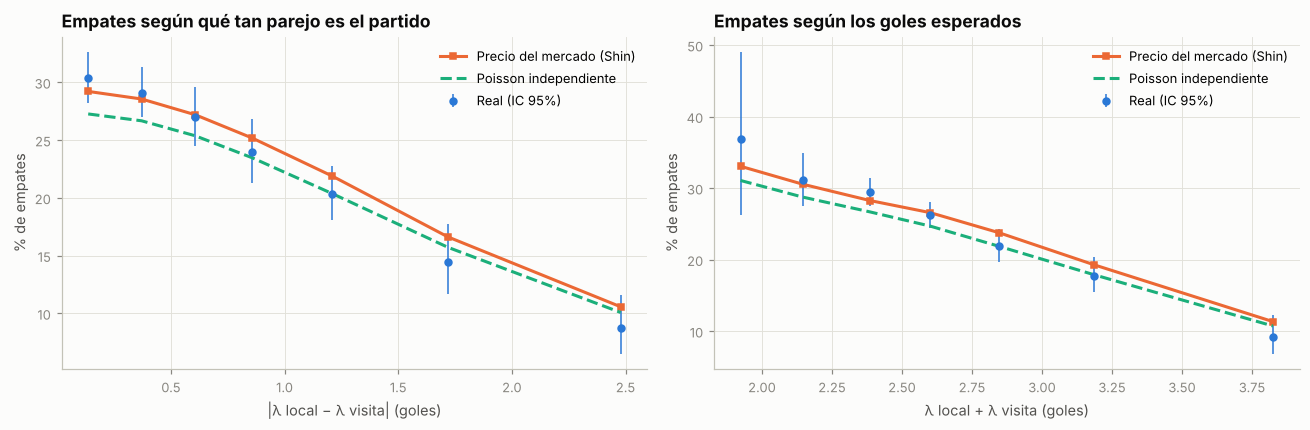

n   real  mercado  poisson
agrupado_por tramo                                     
abs_sup      (0.0, 0.25]  1652 30.400   29.200   27.300
             (0.25, 0.5]  1719 29.100   28.500   26.700
             (0.5, 0.75]  1161 27.000   27.200   25.400
             (0.75, 1.0]   914 24.000   25.200   23.500
             (1.0, 1.5]   1098 20.300   21.900   20.400
             (1.5, 2.0]    512 14.500   16.600   15.700
             (2.0, 4.0]    483  8.700   10.600   10.100
exp_total    (1.0, 2.0]     65 36.900   33.100   31.100
             (2.0, 2.25]   601 31.100   30.500   28.700
             (2.25, 2.5]  2139 29.500   28.300   26.700
             (2.5, 2.75]  2246 26.200   26.600   24.700
             (2.75, 3.0]  1204 21.800   23.800   21.900
             (3.0, 3.5]    928 17.800   19.300   17.900
             (3.5, 6.0]    447  9.200   11.300   10.700

In [9]:
ou["abs_sup"] = (ou["lam_h"] - ou["lam_a"]).abs()
ou["exp_total"] = ou["lam_h"] + ou["lam_a"]
ou["is_draw"] = (ou["hg"] == ou["ag"]).astype(int)
ou["p_draw_pois"] = [np.sum(stats.poisson.pmf(np.arange(11), a) * stats.poisson.pmf(np.arange(11), b))
                     for a, b in zip(ou["lam_h"], ou["lam_a"])]

tables = {}
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col, bins_, title, xl in [
        (axes[0], "abs_sup", [0, 0.25, 0.5, 0.75, 1.0, 1.5, 2.0, 4.0], "Empates según qué tan parejo es el partido", "|λ local − λ visita| (goles)"),
        (axes[1], "exp_total", [1.0, 2.0, 2.25, 2.5, 2.75, 3.0, 3.5, 6.0], "Empates según los goles esperados", "λ local + λ visita (goles)")]:
    t = ou.groupby(pd.cut(ou[col], bins_), observed=True).agg(real=("is_draw", "mean"), mercado=("p_d", "mean"),
                                                               poisson=("p_draw_pois", "mean"), n=("is_draw", "size"),
                                                               x=(col, "mean"))
    lo, hi = wilson(t["real"] * t["n"], t["n"])
    ax.errorbar(t["x"], t["real"] * 100, yerr=[(t["real"] - lo) * 100, (hi - t["real"]) * 100], fmt="o", color=C["blue"],
                ms=4.5, lw=1, label="Real (IC 95%)")
    ax.plot(t["x"], t["mercado"] * 100, color=C["orange"], marker="s", ms=3.5, label="Precio del mercado (Shin)")
    ax.plot(t["x"], t["poisson"] * 100, color=C["aqua"], ls="--", label="Poisson independiente")
    ax.set(title=title, xlabel=xl, ylabel="% de empates")
    ax.legend()
    tables[col] = (t[["n", "real", "mercado", "poisson"]] * [1, 100, 100, 100]).round(1)
plt.tight_layout()
plt.show()
pd.concat(tables, names=["agrupado_por", "tramo"])

> **Lo que dice la data**
> * El empate depende de qué tan parejo es el partido (30.4% cuando los equipos son iguales, 8.7% con más de 2 goles de diferencia esperada) y de cuántos goles se esperan (36.9% con menos de 2, 9.2% con más de 3.5).
> * El mercado "aplana" el empate: lo cobra un poco barato en partidos parejos y de pocos goles (29.2% contra 30.4% real; 33.1% contra 36.9%) y caro en partidos dispares o de muchos goles (10.6% contra 8.7%; 11.3% contra 9.2%). Cada tramo por separado no es significativo, pero el patrón es consistente en todos.
> * La Poisson independiente comete el mismo error de forma más marcada en los partidos parejos.
>
> **Para el modelo:** el empate necesita su propio ajuste según supremacía y total esperado. Este patrón es candidato a edge en el mercado de empate, y hay que validarlo con cuotas de cierre antes de apostar un peso.

## 7. El partido en vivo

Las apuestas en vivo son el mercado de mayor volumen. Un modelo in-play necesita saber cómo cambian las probabilidades con el marcador y el minuto. Uso tres fuentes:

* **Medio tiempo contra final** (25 temporadas de football-data).
* **Minuto de cada gol** de la temporada 2025/26 (openfootball), para ver cuándo se anota.
* La combinación de los dos para estimar la probabilidad de ganar según la ventaja y el minuto.

In [10]:
ht = m.dropna(subset=["hthg"]).copy()
ht["ht_res"] = np.select([ht["hthg"] > ht["htag"], ht["hthg"] == ht["htag"]], ["Local gana", "Empate"], "Visita gana")
ht["ft_res"] = np.select([ht["res"] == "H", ht["res"] == "D"], ["Local gana", "Empate"], "Visita gana")
order = ["Local gana", "Empate", "Visita gana"]
htft = pd.crosstab(ht["ht_res"], ht["ft_res"], normalize="index").reindex(index=order, columns=order)
share_2h = 1 - (ht["hthg"] + ht["htag"]).sum() / (ht["hg"] + ht["ag"]).sum()
print(f"Partidos con medio tiempo: {len(ht):,} | goles en el segundo tiempo: {share_2h:.1%}")

# Favorito del mercado perdiendo al descanso
f = ht.merge(ou[["date", "home", "away", "p_h", "p_a"]], on=["date", "home", "away"], how="inner")
f["fav_home"] = f["p_h"] >= f["p_a"]
f["fav_ht_gd"] = np.where(f["fav_home"], f["hthg"] - f["htag"], f["htag"] - f["hthg"])
f["fav_ft"] = np.where(f["fav_home"], f["res"].map({"H": "Gana", "D": "Empata", "A": "Pierde"}),
                       f["res"].map({"A": "Gana", "D": "Empata", "H": "Pierde"}))
f["fav_p"] = np.maximum(f["p_h"], f["p_a"])
f["tipo_fav"] = pd.cut(f["fav_p"], [0, 0.5, 0.65, 1], labels=["Favorito leve (<50%)", "Favorito (50 a 65%)", "Favorito claro (>65%)"])
comeback = (f[f["fav_ht_gd"].between(-2, 2)]
            .groupby(["tipo_fav", "fav_ht_gd"], observed=True)["fav_ft"].value_counts(normalize=True).unstack()
            .reindex(columns=["Gana", "Empata", "Pierde"]))
comeback["partidos"] = f[f["fav_ht_gd"].between(-2, 2)].groupby(["tipo_fav", "fav_ht_gd"], observed=True).size()
print("Resultado final (columnas, %) según el resultado al medio tiempo (filas):")
display((htft * 100).round(1))
print("Resultado final del favorito (%) según su diferencia de goles al medio tiempo:")
cb = comeback.fillna(0)
cb[["Gana", "Empata", "Pierde"]] = (cb[["Gana", "Empata", "Pierde"]] * 100).round(1)
cb

Partidos con medio tiempo: 9,419 | goles en el segundo tiempo: 55.7%
Resultado final (columnas, %) según el resultado al medio tiempo (filas):


ft_res,Local gana,Empate,Visita gana
ht_res,,,
Local gana,80.600,14.200,5.200
Empate,38.300,36.700,25.000
Visita gana,11.700,20.600,67.600


Resultado final del favorito (%) según su diferencia de goles al medio tiempo:


fav_ft                            Gana  Empata  Pierde  partidos
tipo_fav              fav_ht_gd                                 
Favorito leve (<50%)  -2.000     8.800  10.200  81.000       147
                      -1.000    13.200  28.900  57.900       703
                      0.000     37.400  38.200  24.300      1833
                      1.000     68.500  23.300   8.200       965
                      2.000     91.500   8.100   0.400       258
Favorito (50 a 65%)   -2.000     3.600  12.500  83.900        56
                      -1.000    20.500  26.300  53.200       293
                      0.000     45.600  36.700  17.700       924
                      1.000     80.500  16.000   3.500       599
                      2.000     97.000   2.000   1.000       200
Favorito claro (>65%) -2.000    21.400  21.400  57.100        14
                      -1.000    41.600  21.900  36.500       137
                      0.000     64.600  26.800   8.700       497
                      1.000     90.800   6.900   2.400       466
                      2.000     97.500   2.500   0.000       278

Partidos leídos: 380 | con goles que cuadran con el marcador: 100.0%


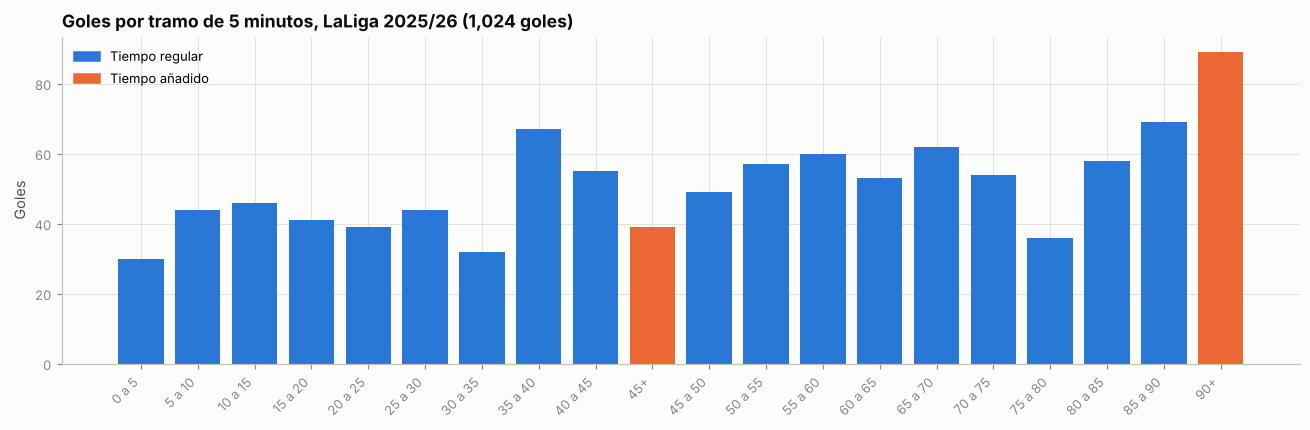

Segundo tiempo: 57.3% | en tiempo añadido: 12.5% | después del 80': 21.1% | penales: 10.2% | autogoles: 2.3%


In [11]:
def parse_goals(path):
    """Partidos y goles con minuto del formato de openfootball (temporada 2025/26)."""
    lines = open(path, encoding="utf-8").read().splitlines()
    match_re = re.compile(r"^\s*(?:\d{1,2}:\d{2})?\s+(.+?)\s+(\d+)-(\d+)(?:\s+\((\d+)-(\d+)\))?\s+(.+?)\s*$")
    goal_re = re.compile(r"(\d{1,3})(?:\+(\d{1,2}))?'(?:\((p|og)\))?")
    matches, i = [], 0
    while i < len(lines):
        mm = match_re.match(lines[i])
        if mm and not lines[i].strip().startswith("("):
            home, hg, ag, away = mm.group(1).strip(), int(mm.group(2)), int(mm.group(3)), mm.group(6).strip()
            block = ""
            if i + 1 < len(lines) and lines[i + 1].strip().startswith("("):
                j = i + 1
                while j < len(lines):
                    block += " " + lines[j].strip()
                    if lines[j].strip().endswith(")") and block.count("(") <= block.count(")"):
                        break
                    j += 1
                i = j
            block = block.strip()[1:-1] if block else ""
            if ";" in block:
                h_part, a_part = block.split(";", 1)
            elif hg > 0 and ag == 0:
                h_part, a_part = block, ""
            elif ag > 0 and hg == 0:
                h_part, a_part = "", block
            else:
                h_part, a_part = block, ""
            goals = [("home", int(g1), int(g2 or 0), kind or "") for g1, g2, kind in goal_re.findall(h_part)]
            goals += [("away", int(g1), int(g2 or 0), kind or "") for g1, g2, kind in goal_re.findall(a_part)]
            matches.append({"home": home, "away": away, "hg": hg, "ag": ag, "goals": goals,
                            "ok": sum(g[0] == "home" for g in goals) == hg and sum(g[0] == "away" for g in goals) == ag})
        i += 1
    return pd.DataFrame(matches)


of = parse_goals(fetch(OPENFOOTBALL.format("2025-26"), DATA / "liga_2025-26.txt"))
print(f"Partidos leídos: {len(of)} | con goles que cuadran con el marcador: {of['ok'].mean():.1%}")
of = of[of["ok"]]
goals = pd.DataFrame([{"match": k, "side": s, "minute": mi, "added": ad, "kind": kd}
                      for k, row in of.iterrows() for s, mi, ad, kd in row["goals"]])
goals["half"] = np.where(goals["minute"] <= 45, 1, 2)
goals["bin"] = np.where(goals["added"] > 0, np.where(goals["minute"] == 45, "45+", "90+"),
                        (np.ceil(goals["minute"] / 5) * 5).clip(5, 90).astype(int).astype(str))
labels_ = [str(b) for b in range(5, 50, 5)] + ["45+"] + [str(b) for b in range(50, 95, 5)] + ["90+"]
counts = goals["bin"].value_counts().reindex(labels_, fill_value=0)

fig, ax = plt.subplots(figsize=(12, 4))
colors = [C["orange"] if l.endswith("+") else C["blue"] for l in labels_]
ax.bar(range(len(labels_)), counts.values, color=colors)
ax.set_xticks(range(len(labels_)), ["0 a 5" if l == "5" else (l if l.endswith("+") else f"{int(l) - 5} a {l}") for l in labels_],
              rotation=45, ha="right")
ax.set(title=f"Goles por tramo de 5 minutos, LaLiga 2025/26 ({len(goals):,} goles)", ylabel="Goles")
ax.legend(handles=[mpl.patches.Patch(color=C["blue"], label="Tiempo regular"),
                   mpl.patches.Patch(color=C["orange"], label="Tiempo añadido")], loc="upper left")
plt.tight_layout()
plt.show()

print(f"Segundo tiempo: {(goals['half'] == 2).mean():.1%} | en tiempo añadido: {(goals['added'] > 0).mean():.1%} | "
      f"después del 80': {((goals['minute'] > 80) | ((goals['minute'] == 90) & (goals['added'] > 0))).mean():.1%} | "
      f"penales: {(goals['kind'] == 'p').mean():.1%} | autogoles: {(goals['kind'] == 'og').mean():.1%}")

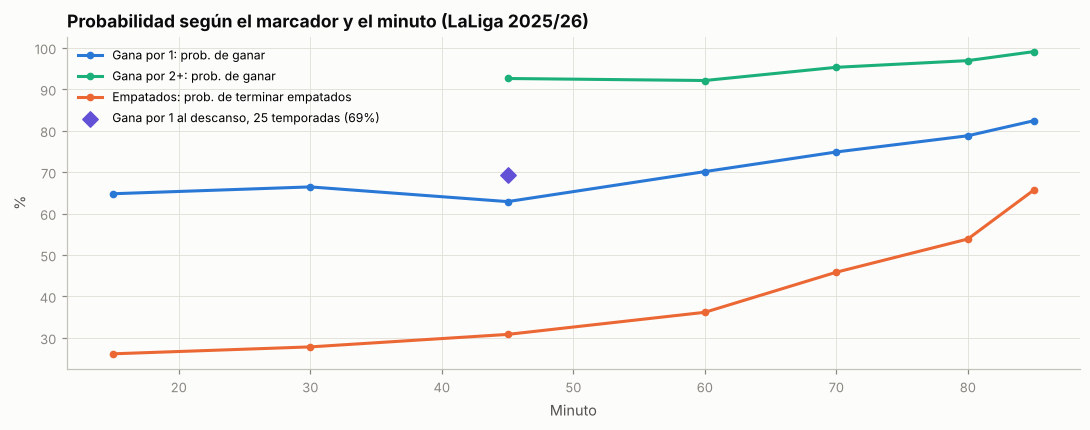

n                             gana                           empata                       
estado Empatados Gana por 1 Gana por 2+ Empatados Gana por 1 Gana por 2+ Empatados Gana por 1 Gana por 2+
t                                                                                                        
15           287         88           5     0.000      0.648       0.600     0.261      0.193       0.200
30           223        137          20     0.000      0.664       0.800     0.278      0.219       0.050
45           159        167          54     0.000      0.629       0.926     0.308      0.251       0.037
60           130        174          76     0.000      0.701       0.921     0.362      0.230       0.079
70           120        175          85     0.000      0.749       0.953     0.458      0.194       0.047
80           104        179          97     0.000      0.788       0.969     0.538      0.190       0.031
85            96        176         108     0.000      0.824       0.991     0.656      0.165       0.009

In [12]:
# Probabilidad de ganar según la ventaja y el minuto (2025/26)
def state_at(goals_list, t):
    """Diferencia de goles (local − visita) al minuto t. El añadido del primer tiempo cuenta como 45."""
    d = 0
    for side, mi, ad, _ in goals_list:
        eff = mi if ad == 0 else (45 if mi == 45 else 90)   # el añadido cuenta al final de cada tiempo
        if eff <= t:
            d += 1 if side == "home" else -1
    return d


minutes = [15, 30, 45, 60, 70, 80, 85]
rows = []
for _, r in of.iterrows():
    final = np.sign(r["hg"] - r["ag"])
    for t in minutes:
        d = state_at(r["goals"], t)
        if d != 0:   # perspectiva del equipo que va ganando
            lead, res = abs(d), np.sign(d) * final
            rows.append({"t": t, "estado": f"Gana por {min(lead, 2)}{'+' if lead >= 2 else ''}", "resultado": res})
        else:
            rows.append({"t": t, "estado": "Empatados", "resultado": 0 if final == 0 else 2})
live = pd.DataFrame(rows)
summary = live.groupby(["estado", "t"]).agg(
    n=("resultado", "size"),
    gana=("resultado", lambda s: (s == 1).mean()),
    empata=("resultado", lambda s: (s == 0).mean()))

fig, ax = plt.subplots(figsize=(10, 4))
for est, col in [("Gana por 1", C["blue"]), ("Gana por 2+", C["aqua"])]:
    s = summary.loc[est]
    s = s[s["n"] >= 30]
    ax.plot(s.index, s["gana"] * 100, marker="o", ms=4, color=col, label=f"{est}: prob. de ganar")
s = summary.loc["Empatados"]
ax.plot(s.index, s["empata"] * 100, marker="o", ms=4, color=C["orange"], label="Empatados: prob. de terminar empatados")
# Ancla con 25 temporadas al medio tiempo
lead1 = ht[(ht["hthg"] - ht["htag"]).abs() == 1]
p_hold = np.mean(np.sign(lead1["hthg"] - lead1["htag"]) == np.sign(lead1["hg"] - lead1["ag"]))
ax.scatter([45], [p_hold * 100], marker="D", s=50, color=C["violet"], zorder=3, label=f"Gana por 1 al descanso, 25 temporadas ({p_hold:.0%})")
ax.set(title="Probabilidad según el marcador y el minuto (LaLiga 2025/26)", xlabel="Minuto", ylabel="%")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
summary.unstack(0).round(3)

> **Lo que dice la data**
> * El 55.7% de los goles se anota en el segundo tiempo (25 temporadas). En 2025/26, 12.5% de los goles llegó en tiempo añadido y 21% después del minuto 80. El tiempo añadido del segundo tiempo es el tramo con más goles de todo el partido.
> * Ganar por un gol al descanso se convierte en victoria 69% de las veces; ir empatado al descanso termina en empate 37%.
> * La fuerza previa sigue pesando en vivo: un favorito claro (más de 65%) que pierde por 1 al descanso todavía gana 42% de las veces; un favorito leve en la misma situación gana solo 13%.
> * Ir ganando por 1 en el minuto 80 todavía deja 21% de probabilidad de no ganar.
>
> **Para el modelo in-play:** la intensidad de gol sube durante el partido y explota en el añadido, y la probabilidad previa sigue importando después de los goles. Un modelo en vivo combina la probabilidad previa con el marcador y el minuto, no solo el marcador.

## 8. Señal contra ruido: qué estadísticas predicen los puntos futuros

Mismo método que en la NFL. Para cada equipo y temporada (desde 2005/06, cuando hay tiros) parto los partidos en dos mitades intercaladas y mido:

* **Estabilidad:** correlación de la estadística consigo misma entre mitades.
* **Poder predictivo:** correlación de la estadística en una mitad con los puntos por partido en la otra.

El **PDO** es la suma del % de conversión (goles / tiros al arco) y el % de atajadas. Se usa en hockey y fútbol como indicador de suerte: si es muy alto, el equipo está convirtiendo y atajando por encima de lo normal.

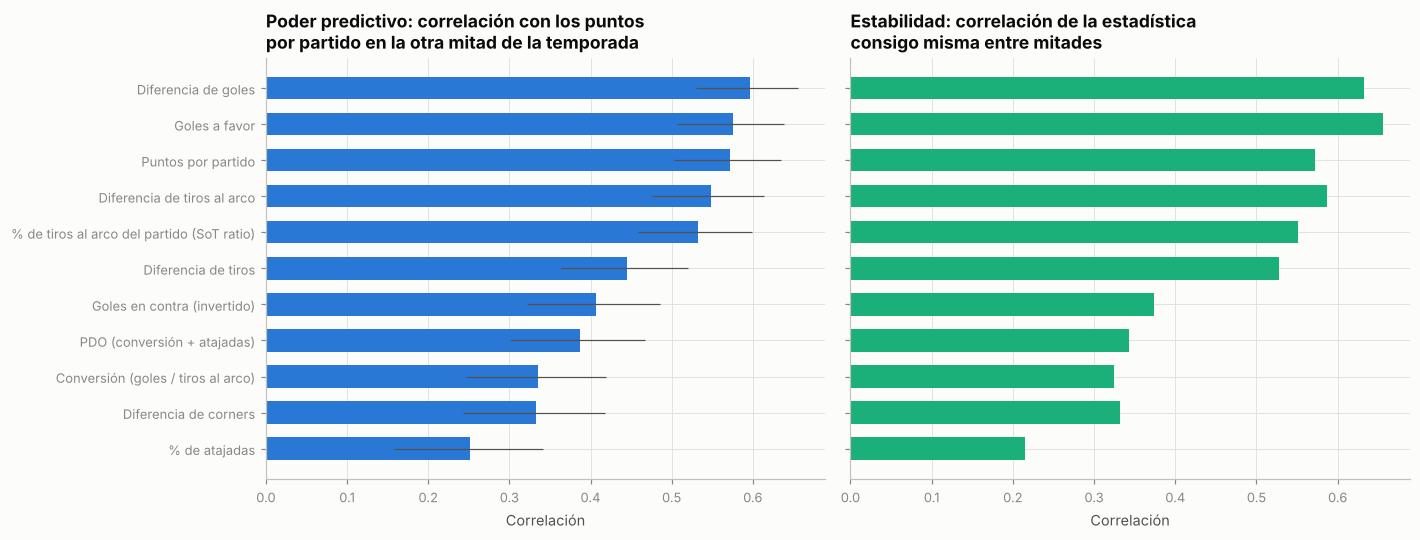

Temporadas de equipo: 400


,estabilidad,predictivo,pred_bajo,pred_alto,n
estadistica,,,,,
Diferencia de goles,0.632,0.597,0.530,0.656,400
Goles a favor,0.656,0.576,0.507,0.638,400
Puntos por partido,0.572,0.572,0.503,0.635,400
Diferencia de tiros al arco,0.587,0.549,0.476,0.614,400
% de tiros al arco del partido (SoT ratio),0.551,0.533,0.459,0.600,400
Diferencia de tiros,0.527,0.445,0.363,0.520,400
Goles en contra (invertido),0.374,0.407,0.321,0.485,400
PDO (conversión + atajadas),0.343,0.387,0.301,0.467,400
Conversión (goles / tiros al arco),0.324,0.336,0.246,0.419,400


In [13]:
tm = pd.concat([
    m.assign(team=m["home"], gf=m["hg"], ga=m["ag"], pts=m["pts_h"], sh=m["hs"], sha=m["as_"], sot=m["hst"],
             sota=m["ast"], co=m["hc"], coa=m["ac"]),
    m.assign(team=m["away"], gf=m["ag"], ga=m["hg"], pts=m["pts_a"], sh=m["as_"], sha=m["hs"], sot=m["ast"],
             sota=m["hst"], co=m["ac"], coa=m["hc"]),
])[["date", "season", "team", "gf", "ga", "pts", "sh", "sha", "sot", "sota", "co", "coa"]]
tm = tm[(tm["season"] >= 2005) & tm["sot"].notna()].sort_values("date")
tm["half"] = np.where(tm.groupby(["season", "team"]).cumcount() % 2 == 0, "A", "B")
a = tm.groupby(["season", "team", "half"]).agg(n=("pts", "size"), pts=("pts", "mean"), gf=("gf", "sum"), ga=("ga", "sum"),
                                                sh=("sh", "sum"), sha=("sha", "sum"), sot=("sot", "sum"), sota=("sota", "sum"),
                                                co=("co", "sum"), coa=("coa", "sum"))
a = a[a["n"] >= 15]
met = pd.DataFrame({
    "Puntos por partido": a["pts"],
    "Diferencia de goles": (a["gf"] - a["ga"]) / a["n"],
    "Diferencia de tiros": (a["sh"] - a["sha"]) / a["n"],
    "Diferencia de tiros al arco": (a["sot"] - a["sota"]) / a["n"],
    "% de tiros al arco del partido (SoT ratio)": a["sot"] / (a["sot"] + a["sota"]),
    "Diferencia de corners": (a["co"] - a["coa"]) / a["n"],
    "Goles a favor": a["gf"] / a["n"],
    "Goles en contra (invertido)": -a["ga"] / a["n"],
    "Conversión (goles / tiros al arco)": a["gf"] / a["sot"],
    "% de atajadas": 1 - a["ga"] / a["sota"],
    "PDO (conversión + atajadas)": a["gf"] / a["sot"] + 1 - a["ga"] / a["sota"],
})
A = met.xs("A", level="half")
B = met.xs("B", level="half")
A, B = A.align(B, join="inner", axis=0)


def corr_ci(x1, x2):
    ok = x1.notna() & x2.notna()
    r = np.corrcoef(x1[ok], x2[ok])[0, 1]
    z, se = np.arctanh(r), 1 / np.sqrt(ok.sum() - 3)
    return r, np.tanh(z - 1.96 * se), np.tanh(z + 1.96 * se), ok.sum()


sig = []
for c in met.columns:
    rel = corr_ci(A[c], B[c])
    p1, p2 = corr_ci(A[c], B["Puntos por partido"]), corr_ci(B[c], A["Puntos por partido"])
    sig.append({"estadistica": c, "estabilidad": rel[0], "predictivo": (p1[0] + p2[0]) / 2,
                "pred_bajo": (p1[1] + p2[1]) / 2, "pred_alto": (p1[2] + p2[2]) / 2, "n": rel[3]})
sig = pd.DataFrame(sig).set_index("estadistica").sort_values("predictivo")

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
yy = np.arange(len(sig))
ax = axes[0]
ax.barh(yy, sig["predictivo"], color=C["blue"], height=0.62)
ax.errorbar(sig["predictivo"], yy, xerr=[sig["predictivo"] - sig["pred_bajo"], sig["pred_alto"] - sig["predictivo"]],
            fmt="none", ecolor=C["ink2"], lw=0.8)
ax.set_yticks(yy, sig.index)
ax.axvline(0, color=C["base"], lw=1)
ax.set(title="Poder predictivo: correlación con los puntos\npor partido en la otra mitad de la temporada", xlabel="Correlación")
ax = axes[1]
ax.barh(yy, sig["estabilidad"], color=C["aqua"], height=0.62)
ax.axvline(0, color=C["base"], lw=1)
ax.set(title="Estabilidad: correlación de la estadística\nconsigo misma entre mitades", xlabel="Correlación")
plt.tight_layout()
plt.show()
print(f"Temporadas de equipo: {len(A):,}")
sig.sort_values("predictivo", ascending=False).round(3)

> **Lo que dice la data**
> * Con media temporada de partidos, la diferencia de goles (0.60) predice los puntos futuros mejor que los propios puntos (0.57) y que la diferencia de tiros al arco (0.55).
> * El ataque es más estable y predictivo que la defensa: goles a favor 0.58 contra goles en contra 0.41.
> * La conversión y las atajadas tienen algo de habilidad en LaLiga (estabilidad 0.32 y 0.22) por la calidad de delanteros y porteros de los grandes, pero mucho menos que el volumen de tiros. Un equipo que convierte muy por encima de lo normal tiende a bajar.
> * Los corners predicen poco (0.33).
>
> **Para el modelo:** usa diferencia de goles y tiros al arco como base, con más peso al ataque, y regresa la conversión y las atajadas hacia la media.

### 8.1 Con 8 partidos jugados, ¿a qué le creo?

La temporada 2026/27 va por la jornada 8. Con tan pocos partidos, los goles tienen mucho ruido. Pruebo qué estadística de los primeros 8 partidos predice mejor los puntos por partido del resto de la temporada.

In [14]:
tm["n_game"] = tm.groupby(["season", "team"]).cumcount()
e8 = tm[tm["n_game"] < 8].groupby(["season", "team"]).agg(
    pts=("pts", "mean"), gd=("gf", "mean"), ga=("ga", "mean"), sot=("sot", "sum"), sota=("sota", "sum"),
    sh=("sh", "sum"), sha=("sha", "sum"))
e8["gd"] = e8["gd"] - e8["ga"]
rest = tm[tm["n_game"] >= 8].groupby(["season", "team"]).agg(pts_resto=("pts", "mean"), n_resto=("pts", "size"))
j = e8.join(rest, how="inner")
j = j[j["n_resto"] >= 20]
cands = {
    "Puntos por partido": j["pts"],
    "Diferencia de goles": j["gd"],
    "Diferencia de tiros al arco": (j["sot"] - j["sota"]) / 8,
    "% de tiros al arco (SoT ratio)": j["sot"] / (j["sot"] + j["sota"]),
    "Diferencia de tiros": (j["sh"] - j["sha"]) / 8,
}
zs = lambda s: (s - s.mean()) / s.std()
cands["Mezcla: dif. de goles + SoT ratio"] = (zs(j["gd"]) + zs(j["sot"] / (j["sot"] + j["sota"]))) / 2
early = pd.Series({k: np.corrcoef(v, j["pts_resto"])[0, 1] for k, v in cands.items()}).sort_values(ascending=False)
print(f"Temporadas de equipo: {len(j):,}")
early.rename("correlación con los puntos del resto de la temporada").round(3).to_frame()

Temporadas de equipo: 400


,correlación con los puntos del resto de la temporada
Diferencia de goles,0.714
Mezcla: dif. de goles + SoT ratio,0.713
Puntos por partido,0.662
Diferencia de tiros al arco,0.657
% de tiros al arco (SoT ratio),0.629
Diferencia de tiros,0.599


> **Lo que dice la data**
> * Después de 8 partidos, la diferencia de goles predice el resto de la temporada (0.71) mejor que la tabla de puntos (0.66) y que los tiros al arco (0.66). Mezclar goles y tiros al arco no mejora (0.71).
> * En la jornada 8 la tabla engaña más que la diferencia de goles. El xG no está en esta base histórica, así que aquí no lo puedo probar; los estudios publicados lo encuentran mejor que goles y tiros, y por eso el predictor lo usa como segunda capa.

## 9. Suerte contra el mercado

Para cada partido, el mercado da puntos esperados: 3 × P(ganar) + 1 × P(empatar). Sumando la temporada se obtiene cuántos puntos "debía" sacar cada equipo según las cuotas previas a cada partido. La diferencia con los puntos reales es la sobre o subperformance.

La pregunta para modelar: ¿esa diferencia persiste (habilidad que el mercado no ve) o se revierte (suerte)?

Correlación de la suerte entre mitades de una temporada: -0.056 (n = 520)
Correlación de la suerte entre una temporada y la siguiente: +0.030 (n = 408)


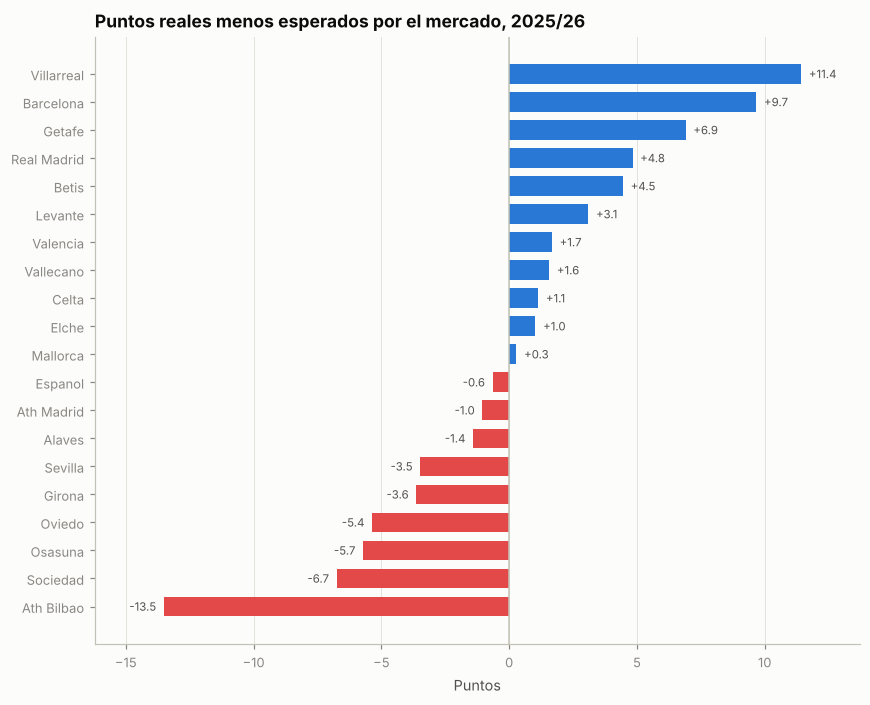

,partidos,puntos,esperados,diferencia
team,,,,
Ath Bilbao,38,45,58.500,-13.500
Sociedad,38,46,52.700,-6.700
Osasuna,38,42,47.700,-5.700
Oviedo,38,29,34.400,-5.400
Girona,38,41,44.600,-3.600
Sevilla,38,43,46.500,-3.500
Alaves,38,43,44.400,-1.400
Ath Madrid,38,69,70.000,-1.000
Espanol,38,46,46.600,-0.600


In [15]:
pm = m.dropna(subset=["oH", "oD", "oA"]).copy()
P = devig_shin(1 / pm[["oH", "oD", "oA"]].values)
pm["xp_h"], pm["xp_a"] = 3 * P[:, 0] + P[:, 1], 3 * P[:, 2] + P[:, 1]
lt = pd.concat([pm.assign(team=pm["home"], pts=pm["pts_h"], xp=pm["xp_h"]),
                pm.assign(team=pm["away"], pts=pm["pts_a"], xp=pm["xp_a"])])[["date", "season", "team", "pts", "xp"]]
lt = lt.sort_values("date")
lt["luck"] = lt["pts"] - lt["xp"]

# Persistencia dentro de la temporada (mitades intercaladas) y entre temporadas
lt["half"] = np.where(lt.groupby(["season", "team"]).cumcount() % 2 == 0, "A", "B")
lh = lt.groupby(["season", "team", "half"])["luck"].mean().unstack()
season_luck = lt.groupby(["season", "team"])["luck"].sum().reset_index()
nxt = season_luck.assign(season=season_luck["season"] - 1).rename(columns={"luck": "luck_next"})
pairs = season_luck.merge(nxt, on=["season", "team"])
print(f"Correlación de la suerte entre mitades de una temporada: {lh['A'].corr(lh['B']):+.3f} (n = {len(lh):,})")
print(f"Correlación de la suerte entre una temporada y la siguiente: {pairs['luck'].corr(pairs['luck_next']):+.3f} (n = {len(pairs):,})")

last_full = 2025
tab = (lt[lt["season"] == last_full].groupby("team").agg(partidos=("pts", "size"), puntos=("pts", "sum"), esperados=("xp", "sum"))
       .assign(diferencia=lambda d: d["puntos"] - d["esperados"]).sort_values("diferencia"))
fig, ax = plt.subplots(figsize=(8, 6.5))
ax.barh(tab.index, tab["diferencia"], color=np.where(tab["diferencia"] >= 0, C["blue"], C["red"]), height=0.7)
ax.axvline(0, color=C["base"], lw=1)
for t, v in tab["diferencia"].items():
    ax.text(v + (0.3 if v >= 0 else -0.3), t, f"{v:+.1f}", va="center", ha="left" if v >= 0 else "right", fontsize=7.5, color=C["ink2"])
ax.set(title=f"Puntos reales menos esperados por el mercado, {label(last_full)}", xlabel="Puntos",
       xlim=(tab["diferencia"].min() * 1.2, tab["diferencia"].max() * 1.2))
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()
tab.round(1)

> **Lo que dice la data**
> * La diferencia entre puntos reales y puntos esperados por el mercado es pura suerte: su correlación entre mitades de una temporada es -0.06 y entre una temporada y la siguiente +0.03.
> * En 2025/26 Villarreal sacó 11.4 puntos más de lo que esperaba el mercado y Barcelona 9.7. Athletic Club sacó 13.5 menos y la Real Sociedad 6.7 menos.
>
> **Para el modelo:** no hay que premiar a los equipos que superan al mercado ni castigar a los que quedan debajo. Las cuotas previas ya resumen casi toda la información; lo que se desvía después es ruido.

## 10. Ratings implícitos del mercado: fuerza y ritmo

Con los λ del mercado se pueden resolver dos ratings por equipo:

* **Fuerza:** cuántos goles de supremacía (λ propio − λ rival) aporta contra un equipo promedio.
* **Ritmo:** cuántos goles agrega al total esperado del partido. Un ritmo alto significa partidos abiertos; uno bajo, partidos cerrados.

El cruce de los dos da un mapa de cómo el mercado ve cada equipo, útil para mercados de goles (over/under) además del 1X2.

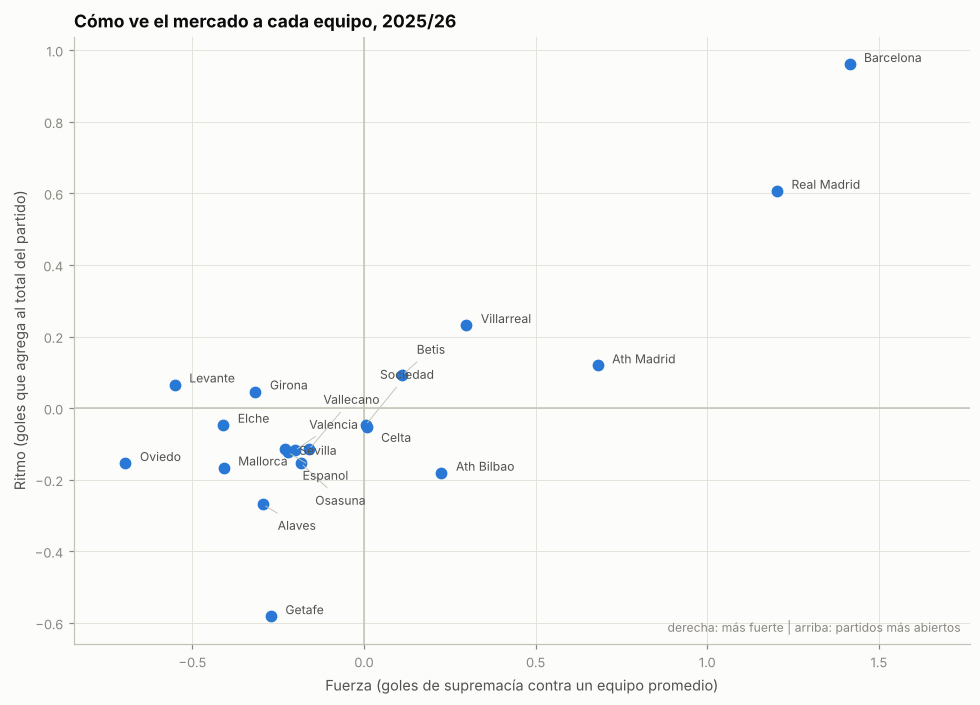

Ventaja de local implícita 2025/26: 0.37 goles


,fuerza,ritmo
Barcelona,1.410,0.960
Real Madrid,1.200,0.610
Ath Madrid,0.680,0.120
Villarreal,0.300,0.230
Ath Bilbao,0.230,-0.180
Betis,0.110,0.090
Celta,0.010,-0.050
Sociedad,0.000,-0.050
Vallecano,-0.160,-0.120
Osasuna,-0.180,-0.150


In [16]:
s25 = ou[ou["season"] == last_full].copy()
s25["tot"] = s25["lam_h"] + s25["lam_a"]
strength, h25 = ratings_ls(s25, "sup")
teams = sorted(set(s25["home"]) | set(s25["away"]))
ix = {t: i for i, t in enumerate(teams)}
X = np.zeros((len(s25) + 1, len(teams) + 1))
for r, (h, a_) in enumerate(zip(s25["home"], s25["away"])):
    X[r, ix[h]], X[r, ix[a_]], X[r, -1] = 1, 1, 1
X[-1, :len(teams)] = 1
beta, *_ = np.linalg.lstsq(X, np.r_[s25["tot"].values, 0], rcond=None)
tempo = pd.Series(beta[:-1], index=teams)
mr = pd.DataFrame({"fuerza": strength, "ritmo": tempo}).sort_values("fuerza", ascending=False)

def repel_labels(ax, x, y, texts, iters=400):
    """Coloca etiquetas sin que se encimen (empuja verticalmente las que chocan)."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    xr, yr = np.ptp(x) or 1, np.ptp(y) or 1
    lx, ly = x / xr + 0.02, y / yr + 0.012
    w = np.array([0.0105 * len(t) for t in texts])
    h = 0.045
    for _ in range(iters):
        moved = False
        for i in range(len(lx)):
            for j in range(i + 1, len(lx)):
                if lx[i] < lx[j] + w[j] and lx[j] < lx[i] + w[i] and abs(ly[i] - ly[j]) < h:
                    s = (h - abs(ly[i] - ly[j])) / 2 + 1e-3
                    up = ly[i] >= ly[j]
                    ly[i] += s if up else -s
                    ly[j] -= s if up else -s
                    moved = True
        if not moved:
            break
    for i, t in enumerate(texts):
        far = abs(ly[i] * yr - y[i]) > 0.03 * yr
        ax.annotate(t, (x[i], y[i]), xytext=(lx[i] * xr, ly[i] * yr), textcoords="data", fontsize=8, color=C["ink2"],
                    va="center", arrowprops=dict(arrowstyle="-", color=C["base"], lw=0.6) if far else None)


fig, ax = plt.subplots(figsize=(9, 6.5))
ax.axhline(0, color=C["base"], lw=1); ax.axvline(0, color=C["base"], lw=1)
ax.scatter(mr["fuerza"], mr["ritmo"], s=45, color=C["blue"], zorder=3)
repel_labels(ax, mr["fuerza"], mr["ritmo"], list(mr.index))
ax.set(title=f"Cómo ve el mercado a cada equipo, {label(last_full)}", xlabel="Fuerza (goles de supremacía contra un equipo promedio)",
       ylabel="Ritmo (goles que agrega al total del partido)")
ax.set_xlim(mr["fuerza"].min() - 0.15, mr["fuerza"].max() + 0.35)
ax.text(0.99, 0.02, "derecha: más fuerte | arriba: partidos más abiertos", transform=ax.transAxes, ha="right", fontsize=8, color=C["muted"])
plt.tight_layout()
plt.show()
print(f"Ventaja de local implícita {label(last_full)}: {h25:.2f} goles")
mr.round(2)

> **Lo que dice la data**
> * En 2025/26 el mercado veía a Barcelona (+1.41 goles) y Real Madrid (+1.20) muy por encima del resto. Atlético (+0.68) era el tercero y después venía un bloque de 15 equipos entre +0.3 y -0.4.
> * Barcelona y Real Madrid también son los que más goles agregan a sus partidos (+0.96 y +0.61). Getafe es el extremo opuesto: el equipo más cerrado de la liga (-0.58).
> * La ventaja de local implícita fue 0.37 goles.
>
> **Para el modelo:** un rating de fuerza no alcanza para over/under. Hace falta un segundo rating de ritmo por equipo.

## 11. Predictor de partidos y prueba contra el mercado

El modelo es el estándar de la industria para fútbol, Dixon y Coles (1997):

1. Cada equipo tiene un parámetro de **ataque** y uno de **defensa**, más una **ventaja de local** común. Los goles esperados del local son exp(media + local + ataque_local − defensa_visita).
2. Los partidos recientes pesan más: el peso cae a la mitad cada cierto número de días (half life).
3. Una corrección ρ ajusta la frecuencia de 0-0, 1-0, 0-1 y 1-1.
4. Incluyo Segunda División para que los equipos recién ascendidos tengan historia.

Antes de usarlo, lo pruebo en la temporada 2025/26 completa: para cada semana ajusto el modelo solo con partidos anteriores y predigo esa semana. Lo comparo con las cuotas de Bet365 sin margen.

In [17]:
def fit_poisson(df, ref_date, half_life):
    """Poisson ponderado: log(λ) = media + local + ataque − defensa del rival."""
    w = 0.5 ** ((ref_date - df["date"]).dt.days.clip(lower=0) / half_life)
    teams = sorted(set(df["home"]) | set(df["away"]))
    ix = {t: i for i, t in enumerate(teams)}
    n, k = len(df), len(teams)
    X = np.zeros((2 * n, 2 * k + 2))
    hi, ai, r = df["home"].map(ix).values, df["away"].map(ix).values, np.arange(n)
    X[:, 0] = 1
    X[r, 1 + hi] = 1; X[r, 1 + k + ai] = -1; X[r, -1] = 1
    X[n + r, 1 + ai] = 1; X[n + r, 1 + k + hi] = -1
    yv = np.r_[df["hg"].values, df["ag"].values]
    res = sm.GLM(yv, X, family=sm.families.Poisson(), freq_weights=np.r_[w, w]).fit_regularized(alpha=1e-4, L1_wt=0.0, maxiter=300)
    b = res.params
    return {"mu": b[0], "att": dict(zip(teams, b[1:k + 1])), "dfn": dict(zip(teams, b[k + 1:2 * k + 1])), "home": b[-1]}


def expected_goals(p, h, a):
    return (np.exp(p["mu"] + p["home"] + p["att"].get(h, 0) - p["dfn"].get(a, 0)),
            np.exp(p["mu"] + p["att"].get(a, 0) - p["dfn"].get(h, 0)))


def score_matrix(lh, la, rho=0.0, maxg=10):
    i = np.arange(maxg + 1)
    M = np.outer(stats.poisson.pmf(i, lh), stats.poisson.pmf(i, la))
    M[0, 0] *= 1 - lh * la * rho; M[0, 1] *= 1 + lh * rho; M[1, 0] *= 1 + la * rho; M[1, 1] *= 1 - rho
    return M / M.sum()


def outcome_probs(M):
    tot = np.add.outer(np.arange(M.shape[0]), np.arange(M.shape[1]))
    return {"H": np.tril(M, -1).sum(), "D": np.trace(M), "A": np.triu(M, 1).sum(),
            "O25": M[tot > 2.5].sum(), "BTTS": M[1:, 1:].sum()}


hist = spain[spain["season"] >= 2021][["date", "home", "away", "hg", "ag", "division", "season", "oH", "oD", "oA"]]
test = hist[(hist["division"] == "SP1") & (hist["season"] == 2025)].copy()
test["wk"] = test["date"].dt.to_period("W-MON")
yt = np.select([test["hg"] > test["ag"], test["hg"] == test["ag"]], [0, 1], 2)
P_mkt = devig_shin(1 / test[["oH", "oD", "oA"]].values)
results = {}
for hl in [180, 365, 540]:
    preds = []
    for wk, gwk in test.groupby("wk"):
        d0 = gwk["date"].min()
        p = fit_poisson(hist[hist["date"] < d0], d0, hl)
        for r in gwk.itertuples():
            pr = outcome_probs(score_matrix(*expected_goals(p, r.home, r.away)))
            preds.append((r.Index, pr["H"], pr["D"], pr["A"]))
    P_mod = pd.DataFrame(preds, columns=["i", "H", "D", "A"]).set_index("i").loc[test.index].values
    results[hl] = P_mod

ll = lambda P: -np.mean(np.log(P[np.arange(len(P)), yt]))
bt = pd.DataFrame({f"Modelo (half life {hl} días)": {"log_loss": ll(P)} for hl, P in results.items()}).T
bt.loc["Mercado (Bet365, Shin)"] = ll(P_mkt)
for w_ in [0.2, 0.5]:
    bt.loc[f"Mezcla {int(w_ * 100)}% modelo con half life 540"] = ll(w_ * results[540] + (1 - w_) * P_mkt)
bt.loc["Frecuencias históricas"] = ll(np.tile(np.bincount(yt, minlength=3) / len(yt), (len(yt), 1)))
print(f"Partidos de prueba: {len(test)} (LaLiga 2025/26)")
bt.sort_values("log_loss")

Partidos de prueba: 380 (LaLiga 2025/26)


,log_loss
"Mercado (Bet365, Shin)",0.962
Mezcla 20% modelo con half life 540,0.963
Mezcla 50% modelo con half life 540,0.965
Modelo (half life 540 días),0.973
Modelo (half life 365 días),0.974
Modelo (half life 180 días),0.980
Frecuencias históricas,1.046


> **Lo que dice la data**
> * En la temporada 2025/26 el mercado (log loss 0.962) le ganó a todas las versiones del modelo (0.973 a 0.980), y mezclarlos no mejora: con 20% de modelo da 0.963.
> * El modelo sí aprende algo real: le gana por mucho a las frecuencias históricas (1.046). El half life largo (540 días) funciona mejor que el corto, igual que en el paper original de Dixon y Coles.
>
> **Para el modelo:** un Dixon-Coles con resultados es el punto de partida, no el final. Para acercarse al mercado faltan xG, alineaciones, lesiones y cuotas de cierre para medir.

### 11.1 Jornada 9 de 2026/27 (domingo 18 de octubre)

Para la temporada en curso uso los resultados de openfootball (jornadas 1 a 7) y agrego la jornada 8 a mano, porque todavía no estaba cargada. Encima del modelo de goles agrego una capa de **xG** de la temporada (StatMuse, al 17 de octubre): mide la calidad de las ocasiones y es mejor predictor que los goles cuando hay pocos partidos.

Los λ finales son el promedio geométrico de los dos modelos. Las cuotas del mercado son de Polymarket y Novig vía Dimers, capturadas la mañana del partido.

In [18]:
MAP = {"CA Osasuna": "Osasuna", "Real Racing Club de Santander": "Santander", "RC Celta de Vigo": "Celta",
       "Deportivo Alavés": "Alaves", "Málaga CF": "Malaga", "Real Sociedad de Fútbol": "Sociedad", "Real Madrid CF": "Real Madrid",
       "Sevilla FC": "Sevilla", "FC Barcelona": "Barcelona", "Club Atlético de Madrid": "Ath Madrid", "Athletic Club": "Ath Bilbao",
       "Villarreal CF": "Villarreal", "Real Betis Balompié": "Betis", "Rayo Vallecano de Madrid": "Vallecano",
       "Valencia CF": "Valencia", "Getafe CF": "Getafe", "Levante UD": "Levante", "Elche CF": "Elche",
       "RCD Espanyol de Barcelona": "Espanol", "RC Deportivo La Coruña": "La Coruna"}


def parse_results(path):
    rows, year, prev_month = [], None, None
    months = {m_: i for i, m_ in enumerate(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"], 1)}
    date = None
    for line in open(path, encoding="utf-8"):
        d = re.match(r"\s*(?:Mon|Tue|Wed|Thu|Fri|Sat|Sun) (\w{3}) (\d{1,2})(?: (\d{4}))?\s*$", line)
        if d:
            mo = months[d.group(1)]
            if d.group(3):
                year = int(d.group(3))
            elif prev_month and mo < prev_month and prev_month >= 8:
                year += 1
            prev_month = mo
            date = pd.Timestamp(year, mo, int(d.group(2)))
            continue
        mm = re.match(r"\s*(?:\d{2}:\d{2})?\s+(.+?)\s+v\s+(.+?)\s{2,}(\d+)-(\d+)", line)
        if mm:
            rows.append({"date": date, "home": MAP.get(mm.group(1).strip(), mm.group(1).strip()),
                         "away": MAP.get(mm.group(2).strip(), mm.group(2).strip()),
                         "hg": int(mm.group(3)), "ag": int(mm.group(4))})
    return pd.DataFrame(rows)


cur = parse_results(fetch(OPENFOOTBALL.format("2026-27"), DATA / "liga_2026-27.txt"))
MD8 = [("Malaga", "Espanol", 1, 1), ("Alaves", "Ath Madrid", 1, 2), ("Barcelona", "Getafe", 3, 0), ("Real Madrid", "Villarreal", 1, 0),
       ("Elche", "Celta", 0, 0), ("Sociedad", "La Coruna", 3, 2), ("Betis", "Osasuna", 5, 2), ("Santander", "Valencia", 2, 2),
       ("Levante", "Sevilla", 3, 3)]   # jornada 8 (9 al 12 de octubre de 2026); Rayo vs Athletic aplazado
have = set(zip(cur["home"], cur["away"]))
extra = pd.DataFrame([{"date": pd.Timestamp("2026-10-11"), "home": h, "away": a, "hg": x, "ag": y_}
                      for h, a, x, y_ in MD8 if (h, a) not in have])
cur = pd.concat([cur, extra], ignore_index=True).assign(division="SP1", season=2026)
print(f"Temporada 2026/27: {len(cur)} partidos ({len(extra)} agregados a mano)")

data = pd.concat([spain[(spain["season"] >= 2021) & (spain["date"] < "2026-08-01")][["date", "home", "away", "hg", "ag", "division", "season"]],
                  cur], ignore_index=True)
REF = pd.Timestamp("2026-10-18")
p_now = fit_poisson(data, REF, 540)

recent = data[(data["division"] == "SP1") & (data["season"] >= 2024)]
lams = [expected_goals(p_now, r.home, r.away) for r in recent.itertuples()]
def nll(rho):
    return -sum(np.log(score_matrix(lh, la, rho, 12)[min(int(x), 12), min(int(y_), 12)]) for (lh, la), x, y_ in zip(lams, recent["hg"], recent["ag"]))
rho = minimize_scalar(nll, bounds=(-0.25, 0.1), method="bounded").x
print(f"Ventaja de local: x{np.exp(p_now['home']):.2f} goles | ρ de Dixon-Coles: {rho:.3f}")

# Capa de xG: StatMuse, temporada 2026/27 al 17 de octubre (partidos, xG, xG en contra, posesión, goles, goles en contra)
xg = pd.DataFrame([
    ("Barcelona", 8, 30.51, 7.78, 70.4, 34, 7), ("Villarreal", 9, 19.30, 11.07, 60.4, 13, 13), ("Ath Madrid", 9, 15.47, 8.96, 59.8, 19, 8),
    ("Betis", 8, 13.65, 15.04, 53.8, 14, 9), ("Ath Bilbao", 6, 9.65, 7.15, 52.5, 7, 6), ("Real Madrid", 8, 20.24, 8.37, 51.8, 19, 8),
    ("Malaga", 8, 6.70, 12.31, 51.7, 4, 13), ("Elche", 9, 10.48, 16.71, 50.8, 11, 17), ("Celta", 8, 6.94, 9.91, 50.0, 8, 6),
    ("Santander", 8, 11.05, 17.52, 48.8, 13, 23), ("Vallecano", 7, 9.22, 12.70, 48.7, 11, 16), ("Sociedad", 8, 9.91, 13.84, 48.0, 12, 15),
    ("La Coruna", 9, 10.18, 11.39, 48.0, 13, 12), ("Valencia", 8, 7.85, 12.86, 47.4, 6, 15), ("Espanol", 9, 10.38, 11.56, 46.4, 11, 12),
    ("Osasuna", 8, 10.28, 13.79, 46.0, 8, 18), ("Levante", 8, 11.65, 16.00, 43.9, 12, 16), ("Sevilla", 8, 9.03, 11.26, 42.1, 13, 12),
    ("Alaves", 8, 10.57, 10.32, 40.9, 12, 8), ("Getafe", 8, 5.89, 10.41, 37.3, 4, 10)],
    columns=["team", "PJ", "xG", "xGA", "posesion", "GF", "GC"]).set_index("team")
xg["xG_pp"], xg["xGA_pp"] = xg["xG"] / xg["PJ"], xg["xGA"] / xg["PJ"]
xg["suerte_goles_pp"] = ((xg["GF"] - xg["GC"]) - (xg["xG"] - xg["xGA"])) / xg["PJ"]
lg = xg["xG"].sum() / xg["PJ"].sum()
hf = np.exp(p_now["home"])

FIXTURES = {  # precios en centavos (local, empate, visita, over 2.5, under 2.5)
    ("Osasuna", "Santander"): (49, 26, 27, 59, 42),
    ("Celta", "Alaves"): (44, 30, 27, 43, 58),
    ("Malaga", "Sociedad"): (29, 27, 46, 54, 47),
    ("Real Madrid", "Sevilla"): (80, 13, 100 / 13, 70, 30),
}
rows = []
for (h, a), (ch, cd, ca, co, cu) in FIXTURES.items():
    gh, ga_ = expected_goals(p_now, h, a)
    xh = lg * np.sqrt(hf) * (xg.loc[h, "xG_pp"] / lg) * (xg.loc[a, "xGA_pp"] / lg)
    xa = lg / np.sqrt(hf) * (xg.loc[a, "xG_pp"] / lg) * (xg.loc[h, "xGA_pp"] / lg)
    lh, la = np.sqrt(gh * xh), np.sqrt(ga_ * xa)
    M = score_matrix(lh, la, rho)
    pr = outcome_probs(M)
    s, so = ch + cd + ca, co + cu
    top = sorted(((M[i, j], f"{i}-{j}") for i in range(6) for j in range(6)), reverse=True)[:3]
    rows.append({"partido": f"{h} vs {a}", "goles_esp": f"{lh:.2f} a {la:.2f}",
                 "modelo_L": pr["H"], "modelo_E": pr["D"], "modelo_V": pr["A"],
                 "mercado_L": ch / s, "mercado_E": cd / s, "mercado_V": ca / s,
                 "modelo_over25": pr["O25"], "mercado_over25": co / so,
                 "marcadores_probables": ", ".join(f"{k} ({v:.0%})" for v, k in top)})
pred = pd.DataFrame(rows).set_index("partido")
display(xg.loc[[t for pair in FIXTURES for t in pair], ["PJ", "GF", "xG", "GC", "xGA", "posesion", "suerte_goles_pp"]].round(2))
pred.round(3)

Temporada 2026/27: 78 partidos (9 agregados a mano)


Ventaja de local: x1.32 goles | ρ de Dixon-Coles: -0.001


,PJ,GF,xG,GC,xGA,posesion,suerte_goles_pp
team,,,,,,,
Osasuna,8,8,10.280,18,13.790,46.000,-0.810
Santander,8,13,11.050,23,17.520,48.800,-0.440
Celta,8,8,6.940,6,9.910,50.000,0.620
Alaves,8,12,10.570,8,10.320,40.900,0.470
Malaga,8,4,6.700,13,12.310,51.700,-0.420
Sociedad,8,12,9.910,15,13.840,48.000,0.120
Real Madrid,8,19,20.240,8,8.370,51.800,-0.110
Sevilla,8,13,9.030,12,11.260,42.100,0.400


,goles_esp,modelo_L,modelo_E,modelo_V,mercado_L,mercado_E,mercado_V,modelo_over25,mercado_over25,marcadores_probables
partido,,,,,,,,,,
Osasuna vs Santander,2.09 a 1.33,0.549,0.210,0.241,0.480,0.255,0.265,0.665,0.584,"2-1 (9%), 1-1 (9%), 2-0 (7%)"
Celta vs Alaves,1.15 a 0.94,0.403,0.299,0.298,0.436,0.297,0.267,0.347,0.426,"1-0 (14%), 1-1 (13%), 0-0 (12%)"
Malaga vs Sociedad,1.15 a 1.25,0.337,0.276,0.387,0.284,0.265,0.451,0.432,0.535,"1-1 (13%), 0-1 (11%), 1-0 (10%)"
Real Madrid vs Sevilla,2.67 a 0.73,0.784,0.138,0.078,0.794,0.129,0.076,0.659,0.700,"2-0 (12%), 3-0 (11%), 1-0 (9%)"


> **Cómo leer esto**
> * Donde modelo y mercado coinciden (Real Madrid vs Sevilla), hay poco que discutir.
> * Donde difieren (el modelo ve más fuertes a Osasuna y a Málaga que el mercado), la prueba de arriba dice que el mercado suele tener razón: tiene alineaciones y lesiones que el modelo no ve.
> * La posesión no entra en el modelo: Málaga tiene 51.7% y es último, Alavés 40.9% y va séptimo. Mide estilo, no calidad.
> * La columna de suerte compara la diferencia de goles real con la de xG por partido: Osasuna (-0.81) ha sido el más castigado de estos ocho equipos y Celta (+0.62) el más afortunado.

## 12. Insights y plan de modelado

### Lo más importante

1. **El mercado es el mejor modelo disponible.** Le ganó a mi Dixon-Coles en la última temporada completa. Su debilidad no está en el promedio sino en los extremos: los longshots están caros y los favoritos un poco baratos.
2. **Quitar bien el margen importa.** Shin o power corrigen la mayor parte del sesgo favorito-longshot; el método multiplicativo no.
3. **El empate es el resultado más difícil.** La Poisson independiente lo subestima en partidos parejos, y el mercado lo aplana: barato en partidos parejos y de pocos goles, caro en partidos dispares.
4. **En vivo mandan el minuto y la fuerza previa.** Los goles se aceleran al final y un favorito claro que pierde al descanso todavía gana 4 de cada 10 veces.
5. **La suerte contra el mercado no persiste.** Lo que un equipo saca de más o de menos frente a las cuotas se revierte.

### Plan de modelado

| Paso | Qué hacer | Cómo se mide |
|---|---|---|
| 1. Base | Dixon-Coles con half life largo, Segunda incluida para los ascendidos y ventaja de local reestimada cada temporada | Log loss contra las cuotas de cierre |
| 2. Mejor información | Reemplazar goles por xG (ESPN o FBref) y sumar alineaciones y lesiones | Si baja el log loss fuera de muestra |
| 3. Empates y totales | Ajuste de empate según supremacía y total esperado, más un rating de ritmo por equipo | Calibración de empates y de over/under |
| 4. En vivo | Intensidad de gol por minuto que combine la probabilidad previa con el marcador | Calibración por minuto y marcador |
| 5. Validación | Walk forward por jornada y medición contra el cierre (CLV), no contra el resultado | Rentabilidad simulada con la cuota real disponible |

**Mi opinión honesta:** el 1X2 de LaLiga es un mercado muy eficiente. Las oportunidades más realistas están en mercados derivados (empates, goles, en vivo) y en comparar precios entre casas, que es justo donde este EDA da ventaja.